# Семинар по теме «Деревья решений»

На семинаре обучим деревья регрессии и классификации, сравним их качество при разной глубине и подберём гиперпараметры с помощью Optuna. Затем рассмотрим структуру дерева и важность признаков. Для выбора настроек используем train и validation, а отдельный test оставим для итоговой оценки.

## Деревья для задачи регрессии

### Краткая теория

Когда мы строим дерево, мы на каждом шаге подбираем такой сплит узла, который уменьшит меру неопределённости модели и как можно точнее сгруппирует данные на два получившихся узла. А для каждого итогового листового узла подбираем константное предсказание. В случае регрессии это обычно среднее арифметическое.

Разберём, как это выглядит с точки зрения математики.

В рамках жадного рекурсивного бинарного разбиения на каждом разбиении дерева регрессии/классификации максимизируем функционал качества:

$$
Q(R, j, t) = H(R) - \left (\frac{|R_\ell|}{|R|} H(R_\ell) + \frac{|R_r|}{|R|} H(R_r)\right),
$$

подобрав оптимальные параметры на текущем сплите:

$$
(j, t) = \operatorname*{argmax}_{j, t} \ Q(R, j, t).
$$




Здесь $R$ обозначает объекты текущего узла, $j$ номер признака, $t$ порог. В левую часть $R_\ell$ попадают объекты с $x_j\le t$, в правую $R_r$ остальные. Веса $|R_\ell|/|R|$ и $|R_r|/|R|$ учитывают размеры частей.

Для регрессии неоднородность узла определим как минимальную среднюю потерю постоянного прогноза:

$$H(R)=\min_{c\in\mathbb R}\frac{1}{|R|}\sum_{(x_i,y_i)\in R}L(y_i,c).$$

Самый применяемый функционал ошибки в задачах регрессии — квадратичная ошибка:

$$
L(y_i, c) = (y_i - c)^2.
$$

Если константное предсказание — среднее арифметическое, неопределённость внутри узла измеряется среднеквадратичной ошибкой (Mean Squared Error, MSE):

$$
H(R) = \frac{1}{|R|} \sum_{(x_i, y_i) \in R} (y_i - \bar{y})^2.
$$




В каждом узле выбираем допустимое разбиение с наибольшим уменьшением взвешенной MSE дочерних узлов. Это жадный локальный выбор. Глубокое дерево может получить нулевую train MSE, если одинаковым признакам не соответствуют разные целевые значения. Проверим, как это связано с качеством на новых объектах.

### Данные

Используем Communities and Crime: статистику по сообществам США. Целевая переменная `ViolentCrimesPerPop` содержит нормированный показатель насильственных преступлений на 100 000 жителей. Значение 0,2 в этой таблице не означает 0,2 преступления. Сначала выделим отложенные выборки, затем проведём EDA на train.

#### Разведочный анализ данных (EDA)

Начнём с загрузки данных и их первичного анализа. Воспользуемся датасетом Communities and Crimes. В этом наборе данных целевой признак ($y$) — уровень насильственной преступности (`ViolentCrimesPerPop`), а остальные колонки ($X$) — различные статистические показатели по сообществам.


Выполним загрузку датасета и посмотрим на его структуру: количество образцов, признаков, примеры значений.

In [ ]:
!pip install ucimlrepo --quiet

In [ ]:
# Импорт библиотек
from ucimlrepo import fetch_ucirepo
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import seaborn as sns

In [ ]:
# Загрузка данных
communities_and_crime = fetch_ucirepo(id=183)
X = communities_and_crime.data.features
y = communities_and_crime.data.targets
# EDA и выбор способов обработки проводим только по train.
X_dev, X_holdout_raw, y_dev, y_holdout = train_test_split(X, y, test_size=0.2, random_state=42)
X, X_val_raw, y, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=42)
X = X.copy()
X.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
1370,48,?,?,Terrellcity,7,0.00,0.62,0.71,0.37,0.05,...,?,0.05,0.06,0.01,?,?,?,?,0.0,?
142,5,?,?,WestMemphiscity,1,0.03,0.55,0.82,0.34,0.03,...,?,0.04,0.16,0.01,?,?,?,?,0.0,?
540,42,17,5616,Bensalemtownship,3,0.08,0.47,0.13,0.83,0.22,...,?,0.06,0.24,0.24,?,?,?,?,0.0,?
586,13,?,?,Albanycity,3,0.11,0.52,1.00,0.15,0.02,...,0.1,0.16,0.12,0.10,0.08,0.03,0.57,1,1.0,0.16
1057,29,?,?,Bridgetoncity,6,0.01,0.42,0.07,0.92,0.08,...,?,0.04,0.10,0.03,?,?,?,?,0.0,?


В `features` находятся 127 столбцов, включая идентификаторы `state`, `county`, `community`, `communityname`, `fold`. Исключим их из предикторов этой учебной модели.

Остальные признаки описывают население (`population`, `PopDens`, `pctUrban`), возрастные группы (`agePct12t21`, `agePct12t29`, `agePct16t24`, `agePct65up`), состав домохозяйств и социально-экономические показатели. В группе признаков полиции есть, например, `PolicPerPop`, `PolicBudgPerPop`, `PctPolicOnPatr`.

Таргет `ViolentCrimesPerPop` находится отдельно. Переменных `murdersPerPop`, `robberyPerPop` и других показателей отдельных преступлений в используемой версии признаков нет.

Содержательные числовые признаки и таргет приведены к диапазону [0, 1]. Идентификаторы к этому утверждению не относятся. Дополнительное масштабирование для дерева не требуется: при строго монотонном преобразовании одного признака сохраняется порядок его значений.

Теперь посмотрим на структуру данных и их распределение.

Для удобства заменим все неизвестные значения (`?`) на `NaN`.

In [ ]:
X = X.replace("?", np.nan)
X.head(3)

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
1370,48,NaN,NaN,Terrellcity,7,0.00,0.62,0.71,0.37,0.05,...,NaN,0.05,0.06,0.01,NaN,NaN,NaN,NaN,0.0,NaN
142,5,NaN,NaN,WestMemphiscity,1,0.03,0.55,0.82,0.34,0.03,...,NaN,0.04,0.16,0.01,NaN,NaN,NaN,NaN,0.0,NaN
540,42,17,5616,Bensalemtownship,3,0.08,0.47,0.13,0.83,0.22,...,NaN,0.06,0.24,0.24,NaN,NaN,NaN,NaN,0.0,NaN


In [ ]:
# Быстрый обзор: сколько строк/столбцов, типы данных
print("X Shape:", X.shape)
X.info()
print('-' * 50)
print('-' * 50)
print("Y Shape:", y.shape)
y.info()

X Shape: (1196, 127)
<class 'pandas.core.frame.DataFrame'>
Index: 1196 entries, 1370 to 19
Columns: 127 entries, state to PolicBudgPerPop
dtypes: float64(99), int64(2), object(26)
memory usage: 1.2+ MB
--------------------------------------------------
--------------------------------------------------
Y Shape: (1196, 1)
<class 'pandas.core.frame.DataFrame'>
Index: 1196 entries, 1370 to 19
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ViolentCrimesPerPop  1196 non-null   float64
dtypes: float64(1)
memory usage: 18.7 KB


Пропуски могут быть представлены NaN или строкой `?`. Тип object ещё не означает, что признак категориальный. После замены `?` переведём содержательные признаки в числа.

In [ ]:
# Первые пять признаков не трогаем, так как они не несут ценности
for col in X.columns[5:]:
    X[col] = pd.to_numeric(X[col], errors="raise")

In [ ]:
# Какие признаки остались категориальными?
X.select_dtypes(include=['object']).columns

Index(['county', 'community', 'communityname'], dtype='object')

Идентификаторы исключим из предикторов. Проверь результат `select_dtypes`: типы столбцов могут зависеть от версии загрузчика.

Посмотрим на распределение признаков в датасете.

In [ ]:
X.describe()

,state,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
count,1196.000000,1196.000000,1196.000000,1196.000000,1196.000000,1196.000000,1196.000000,1196.000000,1196.000000,1196.000000,...,204.000000,1196.000000,1196.000000,1196.000000,204.000000,204.000000,204.000000,204.000000,1196.000000,204.000000
mean,28.610368,5.511706,0.062492,0.461798,0.184181,0.747199,0.150677,0.148403,0.425017,0.495510,...,0.313578,0.067617,0.234532,0.160895,0.177157,0.083578,0.704314,0.446078,0.101982,0.211176
std,16.515200,2.899551,0.139890,0.166461,0.256863,0.247520,0.205961,0.237802,0.160073,0.148022,...,0.234832,0.116880,0.202933,0.228502,0.227872,0.147389,0.213017,0.399549,0.251677,0.191465
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,12.000000,3.000000,0.010000,0.350000,0.020000,0.620000,0.040000,0.020000,0.340000,0.410000,...,0.147500,0.020000,0.100000,0.020000,0.040000,0.020000,0.620000,0.000000,0.000000,0.110000
50%,34.000000,6.000000,0.020000,0.440000,0.060000,0.840000,0.080000,0.040000,0.400000,0.480000,...,0.260000,0.040000,0.170000,0.070000,0.080000,0.030000,0.760000,0.500000,0.000000,0.160000
75%,42.000000,8.000000,0.060000,0.550000,0.240000,0.940000,0.160000,0.160000,0.480000,0.540000,...,0.410000,0.070000,0.290000,0.190000,0.220000,0.070000,0.840000,1.000000,0.000000,0.220000
max,56.000000,10.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.990000,1.000000,1.000000,1.000000


Среди признаков есть отсутствующие значения. Посчитаем, в каких конкретно признаках есть `NaN` и какой процент от всех данных по признаку он занимает.

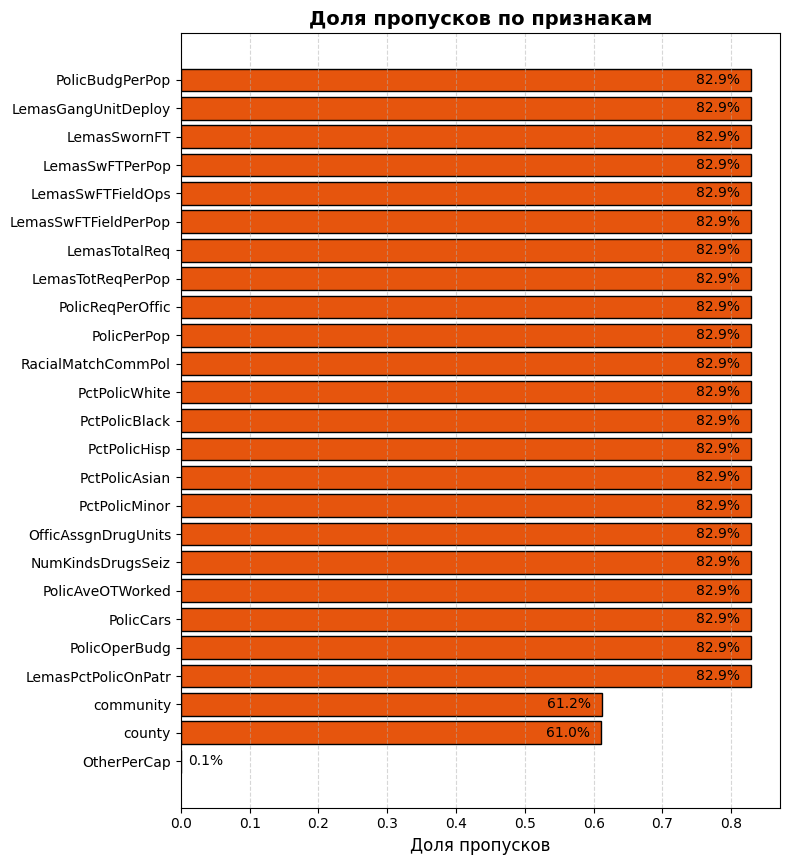

In [ ]:
na_ratio = X.isnull().mean()
na_features = na_ratio[na_ratio > 0].sort_values(ascending=True)  # Снизу вверх — от меньшего к большему

plt.figure(figsize=(8, max(3, 0.35 * len(na_features))))
bars = plt.barh(na_features.index, na_features.values, color="#e6550d", edgecolor="black")

# Подписи процентов справа от столбцов
for num, bar in enumerate(bars):
    width = bar.get_width()
    if num == 0:
      plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f"{width:.1%}", va='center', fontsize=10)
    else:
      plt.text(width - 0.08, bar.get_y() + bar.get_height()/2, f"{width:.1%}", va='center', fontsize=10)

plt.xlabel("Доля пропусков", fontsize=12)
plt.title("Доля пропусков по признакам", fontsize=14, fontweight='bold')
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

По графику видно, какая доля значений каждого признака отсутствует на train. Далее исключим столбцы с долей пропусков не меньше 80%, а оставшиеся пропуски заполним средними train.

Посмотрим теперь на распределение целевого признака.

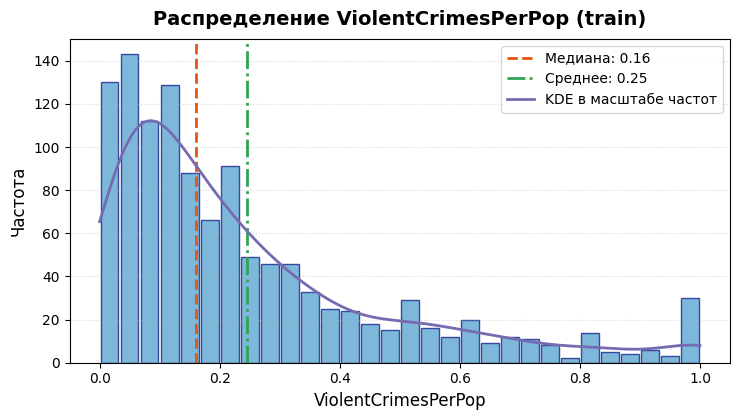

In [ ]:
from scipy.stats import gaussian_kde

ycopy = np.asarray(y)

plt.figure(figsize=(7.5, 4.3))
n, bins, patches = plt.hist(
    ycopy, bins=30, color='#6baed6', edgecolor='#253494', alpha=0.88, rwidth=0.88)

# Сделаем медиану и среднее
plt.axvline(np.median(ycopy), color='#e6550d', linestyle='--', linewidth=2, label=f"Медиана: {np.median(ycopy):.2f}")
plt.axvline(np.mean(ycopy), color='#31a354', linestyle='-.', linewidth=2, label=f"Среднее: {np.mean(ycopy):.2f}")

# И даже добавим плотность
kde = gaussian_kde(ycopy.ravel())
x_kde = np.linspace(ycopy.min(), ycopy.max(), 200)
plt.plot(x_kde, kde(x_kde) * len(ycopy) * (bins[1] - bins[0]), color="#756bb1", linewidth=2, label="KDE в масштабе частот")

plt.title('Распределение ViolentCrimesPerPop (train)', fontsize=14, fontweight='bold', pad=10)
plt.xlabel('ViolentCrimesPerPop', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.legend(fontsize=10, frameon=True)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

Найдём признаки, которые наиболее тесно связаны с целевой переменной. Это даст первое представление о факторах, связанных с уровнем преступности. Также выведем топ-10 признаков с наибольшей по модулю корреляцией с `y`.


In [ ]:
# Соединим X и y вместе для удобства вычисления корреляции
df = X.iloc[:, 5:].copy()
df['target'] = y.values

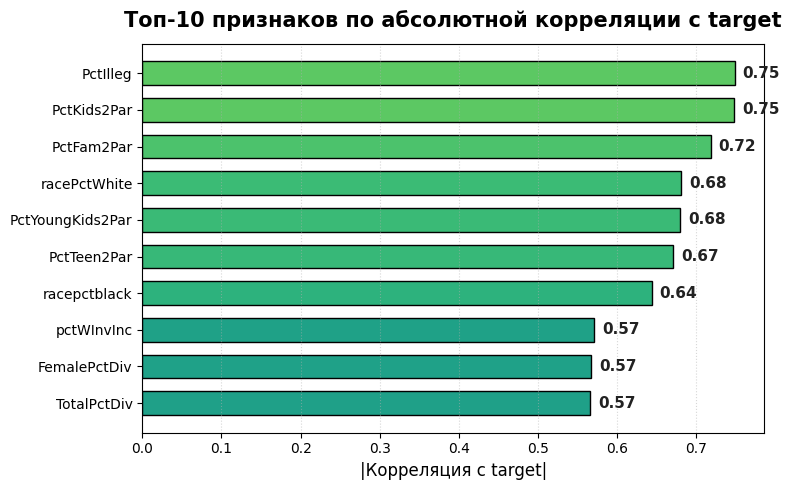

In [ ]:
# Рассчитаем корреляцию
corr = df.corr()['target'].abs().sort_values(ascending=False)

top_n = 10
features = corr.index[1:top_n+1]    # [1:], чтобы не брать сам таргет
values = corr.values[1:top_n+1]

plt.figure(figsize=(8, 5))
bars = plt.barh(features[::-1], values[::-1],
                color=plt.cm.viridis(values[::-1]), edgecolor='black', height=0.65)

# Подписи справа на концах баров
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01, bar.get_y() + bar.get_height()/2,
             f'{width:.2f}', va='center', fontsize=11, fontweight='bold', color="#222")

plt.xlabel('|Корреляция с target|', fontsize=12)
plt.title('Топ-10 признаков по абсолютной корреляции с target',
          fontsize=15, fontweight='bold', pad=12)
plt.grid(axis='x', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

Корреляции показывают линейную связь с таргетом на train. Низкая корреляция не исключает нелинейной зависимости. Само отсутствие признака в топ-10 не является основанием считать его неинформативным.



**ТЕКСТ ТОЛЬКО ДЛЯ СЕМИНАРИСТА**

Интересные результаты: больше всего с уровнем насильственной преступности связана доля детей, рождённых вне брака (`PctIlleg`) и доля детей, живущих в семьях с двумя родителями (`PctKids2Par`, `PctYoungKids2Par`, `PctTeen2Par`). Более того, проценты светло- и темнокожего населения (`racePctWhite`, `racepctblack`) также сильно линейно скоррелированы с целевой переменной. Здесь указаны абсолютные значения, то есть некоторые из этих корреляций могут быть отрицательными.

Но высокая корреляция не обязательно означает причинно-следственную связь и не гарантирует, что этот признак будет наиболее важным для модели дерева решений (которая может учитывать нелинейные эффекты и взаимодействия).


#### Препроцессинг данных

Подготовим train, validation и test одинаковым способом: исключим идентификаторы, выберем столбцы по доле пропусков на train и заполним пропуски средними train. Validation и test преобразуем с уже выбранными столбцами и средними.

Удалим идентификаторы из всех трёх выборок.

In [ ]:
cols_to_drop = ['state', 'county', 'community', 'communityname', 'fold']
X = X.drop(columns=cols_to_drop)
X_val_raw = X_val_raw.drop(columns=cols_to_drop).replace('?', np.nan).apply(pd.to_numeric)
X_holdout_raw = X_holdout_raw.drop(columns=cols_to_drop).replace('?', np.nan).apply(pd.to_numeric)

Большая доля пропусков ограничивает доступную информацию о признаке, но не доказывает его бесполезность. Для этого эксперимента используем порог 80%. Оставшиеся пропуски заполним средними, рассчитанными только по train.

In [ ]:
# Один пропуск в OtherPerCap
X['OtherPerCap'].isna().sum()

np.int64(1)

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

class MissingColumnFilter(TransformerMixin, BaseEstimator):
    def __init__(self, threshold=0.8):
        self.threshold = threshold

    def fit(self, X, y=None):
        self.columns_ = X.columns[X.isna().mean() < self.threshold]
        return self

    def transform(self, X):
        return X.loc[:, self.columns_]

# Сохраняем сырые числовые признаки для обработки внутри CV-фолдов.
X_train_raw = X.apply(pd.to_numeric).copy()
column_filter = MissingColumnFilter().fit(X_train_raw)
imputer = SimpleImputer(strategy='mean')
X = pd.DataFrame(imputer.fit_transform(column_filter.transform(X_train_raw)),
                 columns=column_filter.columns_, index=X_train_raw.index)
X_val = pd.DataFrame(imputer.transform(column_filter.transform(X_val_raw)),
                     columns=X.columns, index=X_val_raw.index)
X_holdout = pd.DataFrame(imputer.transform(column_filter.transform(X_holdout_raw)),
                         columns=X.columns, index=X_holdout_raw.index)
print('Пропусков после импутации:', X.isna().sum().sum())

Пропусков после импутации: 0


Посмотрим на наш датасет.

In [ ]:
X.head()

,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn
1370,0.00,0.62,0.71,0.37,0.05,0.13,0.46,0.48,0.32,0.48,...,0.0,0.14,0.83,0.57,0.67,0.85,0.05,0.06,0.01,0.0
142,0.03,0.55,0.82,0.34,0.03,0.01,0.51,0.53,0.34,0.33,...,0.0,0.01,0.52,0.55,0.73,0.67,0.04,0.16,0.01,0.0
540,0.08,0.47,0.13,0.83,0.22,0.04,0.40,0.53,0.30,0.27,...,0.0,0.19,0.78,0.58,0.56,0.71,0.06,0.24,0.24,0.0
586,0.11,0.52,1.00,0.15,0.02,0.01,0.58,0.57,0.41,0.33,...,0.0,0.02,0.80,0.50,0.69,0.71,0.16,0.12,0.10,1.0
1057,0.01,0.42,0.07,0.92,0.08,0.02,0.35,0.40,0.25,0.44,...,0.0,0.04,0.76,0.64,0.73,0.78,0.04,0.10,0.03,0.0


Разбиение уже выполнено до EDA. Сохраним обучающие данные под именами X_train и y_train. Validation используем при сравнении глубин, test пока не оцениваем.

In [ ]:
X_train, y_train = X, y.squeeze('columns')
y_val = y_val.squeeze('columns')
y_holdout = y_holdout.squeeze('columns')
print('Train:', X_train.shape)
print('Validation:', X_val.shape)
print('Test:', X_holdout.shape)

Train: (1196, 100)
Validation: (399, 100)
Test: (399, 100)


Данные подготовлены. Параметры обработки получены по train и применены к отложенным выборкам. При кросс-валидации заново обучим отбор столбцов и импутацию внутри каждого фолда.

### Неограниченные деревья

#### Обучение неограниченного дерева решений

Используем `DecisionTreeRegressor` из `sklearn.tree`. Ручная реализация дерева рассматривается в домашнем задании этой недели.

In [ ]:
'''model = DecisionTreeRegressor(criterion='squared_error', # Критерий расщепления
                                                            # («squared_error» / «absolute_error»)
     splitter='best',               # Разбиение  «best»/«random»
     max_depth=None,                # Допустимая глубина
     min_samples_split=2,           # Минимальная выборка для разбиения
     min_samples_leaf=1,            # Минимальная мощность листа
     min_weight_fraction_leaf=0.0,  # Аналогично с весом
     max_features=None,             # Признаки для нахождения разбиения
     random_state=None,             # Чтобы можно было воспроизвести результаты
     max_leaf_nodes=None,           # Допустимое число листьев
     min_impurity_decrease=0.0,     # Порог изменения «зашумлённости»
     ccp_alpha=0.0)                 # для стрижки дерева (post-pruning)

model.fit(X, y)''';

Разберём, что делает каждый гиперпараметр.

`criterion` (`'squared_error'` / `'absolute_error'` / `'friedman_mse'` / `'poisson'`) — функция качества разбиения, по которой оценивается «шумность» узлов (чаще всего MSE или MAE).

`splitter `(`'best'` / `'random'`) — способ выбора разбиения в узле: либо лучшее допустимое разбиение, либо лучшее среди случайно предложенных порогов по рассматриваемым признакам.

`max_depth` (`int` или `None`) — максимальная глубина дерева (сколько разбиений можно делать подряд), `None` = без ограничения.

`min_samples_split` (`int`) — минимальное число образцов в узле, необходимое, чтобы попытаться его разделить.

`min_samples_leaf` (`int`) — минимальное число образцов, которое должно оказаться в листе после разбиения.

`min_weight_fraction_leaf` (`float`) — минимальная доля от суммы весов всех образцов, которая должна приходиться на лист.

`max_features` (`int`/`float`/`str` или `None`) — число признаков, которые рассматриваются при поиске лучшего разбиения (`None` = все признаки).

`random_state` (`int`) — зерно генератора случайных чисел для воспроизводимости случайных решений.

`max_leaf_nodes` (`int` или `None`) — максимально допустимое число листьев в дереве, `None` = без ограничения.

`min_impurity_decrease` (`float`) — минимальное уменьшение неоднородности при разбиении, взвешенное долей текущего узла во всей обучающей выборке.

`ccp_alpha` (`float`) — параметр штрафа за число листьев при обрезке дерева (cost-complexity pruning). Чем он больше, тем сильнее обрезка.

В коде выше указаны дефолтные значения гиперпараметров.

Начнём с базового варианта: обучим дерево решений для регрессии без ограничения глубины (и других параметров сложности). Класс `DecisionTreeRegressor` по умолчанию не ограничивает глубину дерева. Рост продолжается, пока листья не станут полностью чистыми (целевые ответы всех наблюдений не станут одинаковыми) или пока допустимых разбиений больше не останется, например при совпадении всех значений признаков в узле.


#### Задание 1

Обучи `DecisionTreeRegressor` (дерево решений для регрессии) на обучающих данных (`X_train`, `y_train`) с параметрами по умолчанию. Используя методы `model.get_depth()` и `model.get_n_leaves()`, выведи полученную глубину дерева и число листьев. Эти значения дадут представление о размере получившегося дерева.

**Заготовка для студента**

```python
# Напиши код здесь: обучение DecisionTreeRegressor и вывод глубины и числа листьев
# tree_unlimited = ...
# ...
# print('Глубина дерева:', ...)
# print('Число листьев:', ...)
```

In [ ]:
# РЕШЕНИЕ
tree_unlimited = DecisionTreeRegressor(random_state=42)
tree_unlimited.fit(X_train, y_train)
print('Глубина дерева:', tree_unlimited.get_depth())
print('Число листьев:', tree_unlimited.get_n_leaves())

Глубина дерева: 23
Число листьев: 897


Сравни полученные глубину и число листьев с размером train. Каким ожидаешь качество на train и validation? Почему глубокое дерево может переобучиться?

**Ответ.** Получилось дерево глубины 23 с 897 листьями при 1196 объектах train. Многие листья содержат очень мало наблюдений. Такая модель может почти точно воспроизвести train, но на новых объектах локальные правила могут работать хуже. Проверим это по метрикам.

#### Оценка качества неограниченной модели

 Оценим качество получившегося дерева решений на обучающей и валидационной выборках. Будем использовать метрики Mean Squared Error (MSE) и коэффициент детерминации $R^2$ для количественной оценки. MSE измеряет средний квадрат ошибки прогноза, а $R^2$ показывает долю объяснённой вариативности. Значение $R^2=1$ — это идеальное предсказание.

Вычислим MSE и $R^2$ на обучающем и валидационном наборах для модели `tree_unlimited`, которую обучали выше.

In [ ]:
y_train_pred = tree_unlimited.predict(X_train)
y_val_pred = tree_unlimited.predict(X_val)
mse_train = mean_squared_error(y_train, y_train_pred)
mse_val = mean_squared_error(y_val, y_val_pred)
r2_train = r2_score(y_train, y_train_pred)
r2_val = r2_score(y_val, y_val_pred)

print(f'MSE (train): {mse_train:.4f}')
print(f'MSE (validation): {mse_val:.4f}')
print(f'R^2 (train): {r2_train:.4f}')
print(f'R^2 (validation): {r2_val:.4f}')

MSE (train): 0.0000
MSE (validation): 0.0367
R^2 (train): 1.0000
R^2 (validation): 0.3103


На train MSE округляется до 0,0000, R² равен 1,000. На validation MSE около 0,0367, R² около 0,310. Такой разрыв указывает на переобучение. Далее проверим, улучшит ли ограничение глубины качество на той же validation.

#### Визуализация дерева решений

Если наглядно представить логику принятия решений, то можно визуализировать модель деревьев решений. Но полностью визуализировать глубокое дерево может быть трудно из-за его размера. Отобразим верхние уровни дерева, чтобы увидеть, по каким признакам и порогам происходит первое ветвление.

#### Задание 2

Визуализируй `tree_unlimited` с помощью `tree.plot_tree`. Укажи `feature_names=X.columns`, `max_depth=2` и `filled=True`. Ограничение глубины рисунка не меняет обученную модель. Посмотри, какие признаки использованы в верхних узлах.

**Заготовка для студента**

```python
plt.figure(figsize=(14, 7))
# Напиши код здесь: визуализация верхних уровней дерева
# ...
# ...

plt.title("Верхние уровни дерева решений", fontsize=18, fontweight='bold', pad=16)
plt.axis('off')                  # уберём ненужные оси вокруг
plt.tight_layout()
plt.show()
```

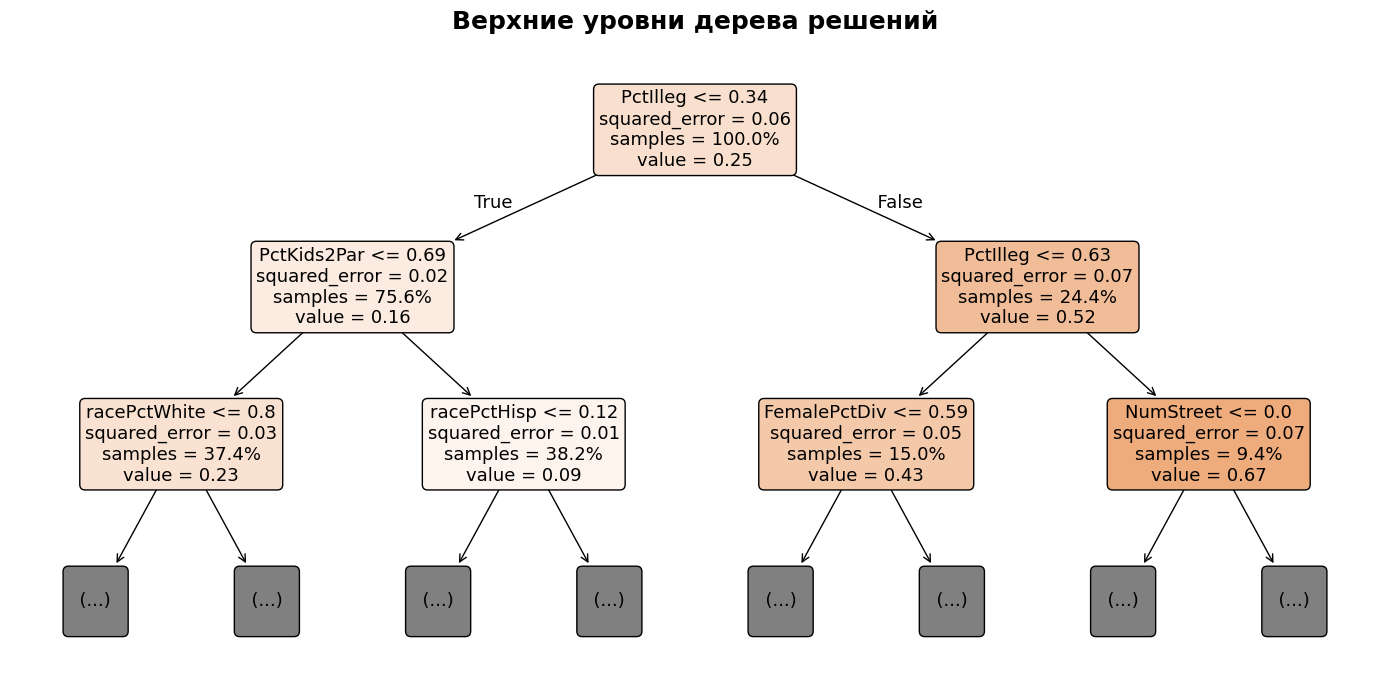

In [ ]:
# РЕШЕНИЕ
plt.figure(figsize=(14, 7))

# Визуализируем первые уровни
tree.plot_tree(
    tree_unlimited,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    max_depth=2,                 # Верхние уровни, чтобы не перегружать
    fontsize=13,
    impurity=True,
    proportion=True,             # Покажет процент объектов в каждом узле
    precision=2                  # Округление чисел
)
plt.title("Верхние уровни дерева решений", fontsize=18, fontweight='bold', pad=16)
plt.axis('off')                  # Уберём ненужные оси вокруг
plt.tight_layout()
plt.show()

**Вопрос.** Какой признак выбран в корне? Почему его разбиение оказалось лучшим по MSE? Можно ли по этому результату сделать причинный вывод о влиянии признака на преступность?

**Ответ.** В корне используется `PctIlleg` с порогом около 0,34. Это разбиение сильнее остальных допустимых вариантов уменьшает MSE на train. В дочерних узлах сравнение проводится уже на их подвыборках, поэтому положение выше в дереве не гарантирует большего вклада во всей модели. Разбиения отражают предсказательные зависимости и не устанавливают причинные связи.

Полная структура дерева очень сложная и с большой глубиной, поэтому глубже двух-трёх уровней визуализировать сложно. Сегодня мы ещё ограничим сложность дерева, чтобы улучшить качество на validation и облегчить интерпретацию.

Далее сравним модели с ограниченной глубиной на общей validation.

### Ограниченные деревья: борьба с переобучением

#### Эксперимент: влияние максимальной глубины дерева

Один из ключевых гиперпараметров дерева решений — максимальная глубина (`max_depth`). Ограничивая глубину, мы сокращаем сложность модели, это поможет избежать переобучения. Проведём эксперимент: обучим несколько деревьев с различной максимальной глубиной и посмотрим, как меняется качество на обучающей и валидационной выборках.

#### Задание 3

Напиши цикл, который будет проходить по различным значениям `max_depth`: от 1 до 24. Это выбранный диапазон эксперимента, а не теоретический предел глубины. Для каждого значения глубины обучи `DecisionTreeRegressor` с заданной глубиной на обучающих данных и вычисли $R^2$ на обучающей и валидационной выборках. Можешь использовать метод `model.score`(x, y):

https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html#sklearn.tree.DecisionTreeRegressor.score.

**Заготовка для студента**

```python
# Напиши код здесь: обучение и тестирование деревьев с разными глубинами
# train_scores = ...
# val_scores = ...
# for d in range(1, 25):
#     model = ...
#     ...
#     ...
#     ...
```

In [ ]:
# РЕШЕНИЕ
train_scores = []
val_scores = []
for d in range(1, 25):
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))    # R^2 на тренировке
    val_scores.append(model.score(X_val, y_val))       # R^2 на validation

Построим график зависимости тренировочного и валидационного $R^2$ от глубины дерева.

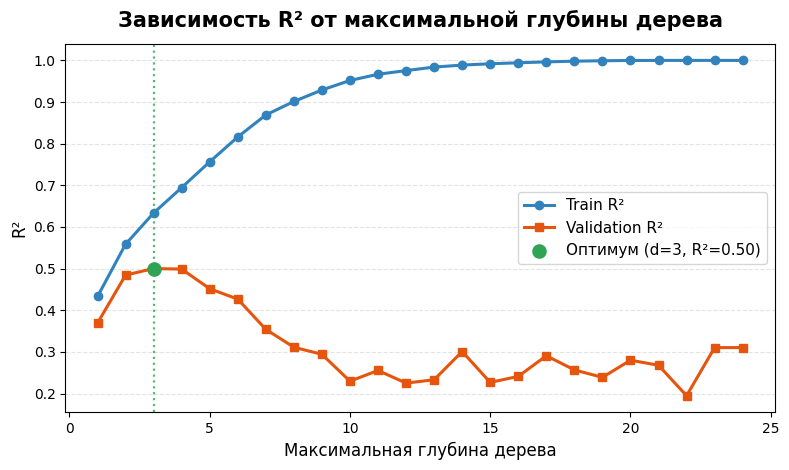

In [ ]:
plt.figure(figsize=(8, 4.8))
depths = np.arange(1, 25)

plt.plot(depths, train_scores, label='Train R²', marker='o', linewidth=2.2, color="#3182bd")
plt.plot(depths, val_scores, label='Validation R²', marker='s', linewidth=2.2, color="#e6550d")

# Отметим максимум на validation
best_idx = np.argmax(val_scores)
plt.scatter(depths[best_idx], val_scores[best_idx], color="#31a354", s=90, zorder=5, label=f'Оптимум (d={depths[best_idx]}, R²={val_scores[best_idx]:.2f})')
plt.axvline(depths[best_idx], color="#31a354", linestyle=':', linewidth=1.6, alpha=0.8)

plt.xlabel('Максимальная глубина дерева', fontsize=12)
plt.ylabel('R²', fontsize=12)
plt.title('Зависимость R² от максимальной глубины дерева', fontsize=15, fontweight='bold', pad=12)
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.legend(fontsize=11, frameon=True)
plt.tight_layout()
plt.show()

In [ ]:
# Видим на графике лучшую глубину по validation
best_index = max(range(len(val_scores)), key=lambda i: val_scores[i])
print('Оптимальная max_depth по validation:', depths[best_index])
print(f'R^2 при оптимальной глубине: {val_scores[best_index]:.3f}')

Оптимальная max_depth по validation: 3
R^2 при оптимальной глубине: 0.500


С увеличением глубины train R² растёт или остаётся прежним. Найди максимум validation R² на графике и сравни его с результатом глубокого дерева. Лучшее значение относится к этому разбиению и рассмотренному диапазону глубин.

**Для преподавателя.** Максимум validation R² около 0,500 получен при глубине 3. У неограниченного дерева было около 0,310. При дальнейшем росте глубины train R² стремится к 1, а validation в целом ухудшается. В этом опыте ограничение глубины уменьшило переобучение.

Ограничение глубины уменьшает гибкость дерева. Слишком сильное ограничение может привести к недообучению, слишком слабое к переобучению. Это связано с компромиссом между смещением и дисперсией, но две кривые train/validation не измеряют компоненты bias и variance. Для их оценки нужны повторные обучающие выборки.

Пока мы не перешли к следующей секции, **вопрос**.

Как изменение других гиперпараметров (например, `min_samples_leaf` — минимального числа образцов в листе) влияет на поведение модели? Почему регулирование размера листьев или минимального числа образцов для разбиения — это альтернатива ограничению глубины?

**Ответ**

Увеличение `min_samples_leaf` не даст дереву дробиться на листья с малым числом объектов, что сгладит предсказания и уменьшит склонность к переобучению. Аналогично, задавая минимальный размер узла, мы не даём дереву расти вглубь вплоть до единичных выборок, что контролирует сложность так же, как и ограничение максимальной глубины.

Мы экспериментально установили, что ограничение глубины дерева может значительно повысить обобщающую способность модели. На практике помимо `max_depth` часто настраивают и другие параметры, которые влияют на размер и структуру дерева. Например, минимальное число образцов в листе, минимальное число образцов для разделения узла. В следующем разделе мы автоматизируем подбор оптимальных параметров с `Optuna`.

#### Pre-pruning: подбор гиперпараметров

GridSearchCV оценивает все комбинации из заданной сетки. При большом числе параметров это дорого. Optuna последовательно предлагает новые комбинации с учётом предыдущих результатов. Её расход ресурсов зависит от числа попыток, стоимости обучения и пространства поиска. В этом эксперименте ограничим поиск 300 попытками и 600 секундами.

In [ ]:
!pip install optuna --quiet

import optuna
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error

/private/tmp/week5-review-20261003/venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


##### Задание 4.1

Используй `Optuna` для подбора оптимальной комбинации гиперпараметров для `DecisionTreeRegressor`. Используй 5-кратную кросс-валидацию (cv=5) и метрику  $R^2$ для оценки. После поиска выведи лучшие значения гиперпараметров и соответствующее качество на кросс-валидации. Для этого ты можешь использовать атрибуты исследования `study` `best_value` и `best_params`.

https://optuna.readthedocs.io/en/stable/

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html

In [ ]:
# РЕШЕНИЕ

# Функция-цель для Optuna
def objective(trial):

    # Пространство поиска
    params = {

        # 1. Структура/глубина
        "max_depth": trial.suggest_int("max_depth", 2, 25),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 2, 200, log=True),

        # 2. Размер узла/листа
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 100),
        "min_samples_leaf":  trial.suggest_int("min_samples_leaf", 1, 100),

        # 3. Критерий + способ сплита
        "criterion": trial.suggest_categorical(
            "criterion", ["squared_error", "friedman_mse",
                          "absolute_error"]),
        "splitter": trial.suggest_categorical("splitter", ["best", "random"]),

        # 4. Сколько фичей просматривать
        "max_features": trial.suggest_categorical(
            "max_features", [None, "sqrt", "log2"]),

        # 5. Pre-pruning
        "min_impurity_decrease": trial.suggest_float(
            "min_impurity_decrease", 1e-7, 1e-2, log=True)

    }

    model = make_pipeline(
        MissingColumnFilter(), SimpleImputer(strategy="mean"),
        DecisionTreeRegressor(random_state=42, **params)
    )

    # 5-кратная кросс-валидация, метрика — R^2
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    r2 = cross_val_score(model, X_train_raw, y_train,
                               scoring="r2",
                               cv=cv, n_jobs=-1)

    return r2.mean()

# Запускаем исследование (300 trials)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=300, timeout=600)

print("Лучшее значение R^2:", study.best_value)
print("Лучшие гиперпараметры:", study.best_params)

[I 2026-10-04 00:29:57,437] A new study created in memory with name: no-name-eabbc8f1-0d84-422a-afac-4959f0196c0e


[I 2026-10-04 00:30:36,924] Trial 0 finished with value: 0.43475515169020645 and parameters: {'max_depth': 10, 'max_leaf_nodes': 158, 'min_samples_split': 74, 'min_samples_leaf': 60, 'criterion': 'squared_error', 'splitter': 'best', 'max_features': 'log2', 'min_impurity_decrease': 0.0014528246637516035}. Best is trial 0 with value: 0.43475515169020645.


[I 2026-10-04 00:30:37,663] Trial 1 finished with value: 0.3797458885603521 and parameters: {'max_depth': 7, 'max_leaf_nodes': 4, 'min_samples_split': 20, 'min_samples_leaf': 31, 'criterion': 'squared_error', 'splitter': 'best', 'max_features': 'log2', 'min_impurity_decrease': 0.000843101393208247}. Best is trial 0 with value: 0.43475515169020645.


[I 2026-10-04 00:30:37,997] Trial 2 finished with value: 0.5473400638048938 and parameters: {'max_depth': 6, 'max_leaf_nodes': 19, 'min_samples_split': 60, 'min_samples_leaf': 5, 'criterion': 'squared_error', 'splitter': 'random', 'max_features': None, 'min_impurity_decrease': 0.00026373339933815276}. Best is trial 2 with value: 0.5473400638048938.


[I 2026-10-04 00:30:38,284] Trial 3 finished with value: 0.21085054321544483 and parameters: {'max_depth': 12, 'max_leaf_nodes': 3, 'min_samples_split': 51, 'min_samples_leaf': 4, 'criterion': 'squared_error', 'splitter': 'random', 'max_features': 'log2', 'min_impurity_decrease': 0.0007510418138777549}. Best is trial 2 with value: 0.5473400638048938.


...

[I 2026-10-04 00:39:19,772] Trial 296 finished with value: 0.585481911044668 and parameters: {'max_depth': 18, 'max_leaf_nodes': 76, 'min_samples_split': 70, 'min_samples_leaf': 32, 'criterion': 'squared_error', 'splitter': 'best', 'max_features': None, 'min_impurity_decrease': 0.00013715516045374537}. Best is trial 124 with value: 0.5933458355763309.


[I 2026-10-04 00:39:21,065] Trial 297 finished with value: 0.573236610186153 and parameters: {'max_depth': 22, 'max_leaf_nodes': 55, 'min_samples_split': 47, 'min_samples_leaf': 41, 'criterion': 'squared_error', 'splitter': 'best', 'max_features': None, 'min_impurity_decrease': 0.00011132340652976163}. Best is trial 124 with value: 0.5933458355763309.


[I 2026-10-04 00:39:22,263] Trial 298 finished with value: 0.5876333442168253 and parameters: {'max_depth': 22, 'max_leaf_nodes': 54, 'min_samples_split': 63, 'min_samples_leaf': 35, 'criterion': 'squared_error', 'splitter': 'best', 'max_features': None, 'min_impurity_decrease': 0.00016086594192518845}. Best is trial 124 with value: 0.5933458355763309.


[I 2026-10-04 00:39:22,828] Trial 299 finished with value: 0.573260408246041 and parameters: {'max_depth': 15, 'max_leaf_nodes': 176, 'min_samples_split': 66, 'min_samples_leaf': 40, 'criterion': 'squared_error', 'splitter': 'best', 'max_features': None, 'min_impurity_decrease': 0.00017400438290228785}. Best is trial 124 with value: 0.5933458355763309.


Лучшее значение R^2: 0.5933458355763309
Лучшие гиперпараметры: {'max_depth': 18, 'max_leaf_nodes': 128, 'min_samples_split': 72, 'min_samples_leaf': 31, 'criterion': 'squared_error', 'splitter': 'best', 'max_features': None, 'min_impurity_decrease': 0.00023256477433558496}


Изобразим ход оптимизации.

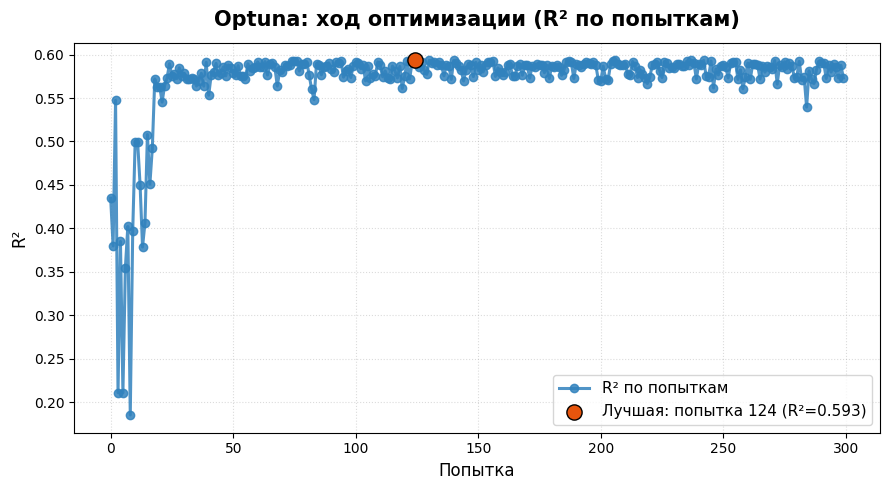

In [ ]:
# DataFrame со всеми попытками
df = study.trials_dataframe()

plt.figure(figsize=(9, 5))
plt.plot(df["number"], df["value"], marker='o', color="#3182bd", linewidth=2.2, alpha=0.85, label="R² по попыткам")

# Отметим максимум
best_idx = df["value"].idxmax()
best_trial = df.loc[best_idx, "number"]
best_value = df.loc[best_idx, "value"]

plt.scatter(best_trial, best_value,
            color="#e6550d", s=120, edgecolor='black', zorder=5,
            label=f'Лучшая: попытка {best_trial} (R²={best_value:.3f})')

plt.xlabel("Попытка", fontsize=12)
plt.ylabel("R²", fontsize=12)
plt.title("Optuna: ход оптимизации (R² по попыткам)", fontsize=15, fontweight='bold', pad=12)
plt.grid(True, linestyle=':', alpha=0.45)
plt.legend(fontsize=11, frameon=True)
plt.tight_layout()
plt.show()

In [ ]:
# plotly используется для интерактивной визуализации.
import plotly

In [ ]:
import optuna.visualization as vis
import plotly.io as pio

# Выберем светлую тему для интерактива
pio.templates.default = "plotly_white"

fig = vis.plot_param_importances(
    study,
    target_name="R²",  # Подпись оси
)
# Тюнинг заголовка, шрифта, ширины и цветов
fig.update_layout(
    title={
        "text": "Важность гиперпараметров (Optuna)",
        "x": 0.5,
        "font": {"size": 22, "family": "Arial", "color": "#222"}
    },
    xaxis_title="Оценка важности гиперпараметра",
    yaxis_title="Гиперпараметр",
    font=dict(size=14, family="Arial"),
    width=800,
    height=500,
    margin=dict(l=80, r=30, t=70, b=60)
)
fig.update_traces(marker_color="#756bb1", marker_line_color='#333', marker_line_width=1.5)
fig.show()

**Для преподавателя.** Значение `study.best_value` используется при выборе параметров и может быть оптимистичным. Финальный test выделен заранее и не участвовал ни в EDA, ни в выборе глубины, ни в Optuna. На нём однократно оценим выбранную по CV модель.

##### Задание 4.2

Обучи `DecisionTreeRegressor` с `study.best_params` на подготовленном train. Однократно рассчитай R² на `X_holdout`, `y_holdout`. Это итоговая тестовая оценка. По ней больше не подбираем параметры.

In [ ]:
# Решение
best_params = study.best_params
best_tree = DecisionTreeRegressor(random_state=42, **best_params)
best_tree.fit(X_train, y_train)
y_pred_holdout = best_tree.predict(X_holdout)
print(f"Итоговый test R²: {r2_score(y_holdout, y_pred_holdout):.3f}")

Итоговый test R²: 0.520


Pre-pruning ограничивает рост дерева во время обучения. Такое ограничение может улучшить обобщение, но слишком ранняя остановка способна исключить полезные последующие разбиения. Параметры выбирают по validation или CV.

### Важность признаков

В деревьях решений важность признаков измеряется через суммарное уменьшение функции неопределённости (в нашем случае — MSE) при разбиениях, в которых участвует данный признак. Для каждого узла дерева вычисляют, насколько упала неопределённость после сплита по этому признаку, учитывают долю объектов, попавших в узел, и складывают такие вклады по всем узлам.

Значения `feature_importances_` нормированы так, что их сумма равна 1 при наличии разбиений. У дерева без разбиений все значения нулевые. Это важность для обученной модели, а не причинный эффект признака.

На будущих неделях мы будем изучать ансамблевые методы. В этих методах значения важности усредняют по всем деревьям, что даёт более стабильную оценку вклада каждого признака.

#### Задание 5

Используя полученное с помощью pre-pruning дерево `best_tree`, выведи важность признаков датасета.
Используй атрибут `feature_importances_` обученного дерева.

In [ ]:
# РЕШЕНИЕ
importances = best_tree.feature_importances_
feature_names = X.columns
# Получим индексы сортировки по убыванию важности
indices = np.argsort(importances)[::-1]
top_n = 5
top_features = feature_names[indices[:top_n]]
top_importances = importances[indices[:top_n]]
print('Топ-5 признаков по важности:')
for i in range(top_n):
    print(f"{i+1}.{top_features[i]} - importance {top_importances[i]:.4f}")

Топ-5 признаков по важности:
1.PctIlleg - importance 0.7509
2.PctKids2Par - importance 0.1003
3.FemalePctDiv - importance 0.0371
4.racePctWhite - importance 0.0345
5.NumStreet - importance 0.0335


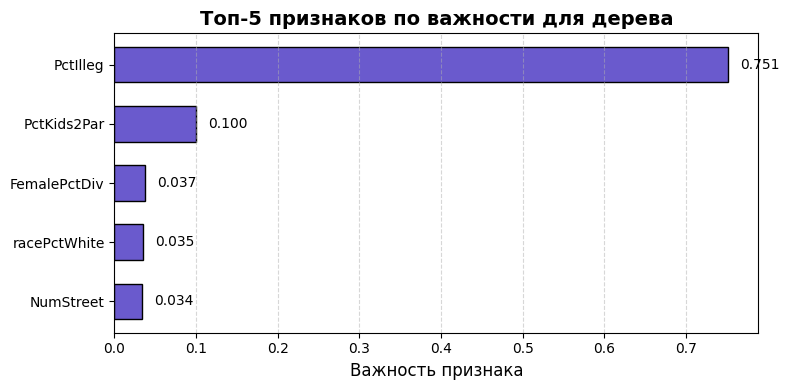

In [ ]:
# Нарисуем то, что получили
plt.figure(figsize=(8, 4))
bars = plt.barh(top_features[::-1], top_importances[::-1],
                color='slateblue', edgecolor='black', height=0.6)

# Добавим значения справа от столбцов
for bar in bars:
    width = bar.get_width()
    plt.text(width + max(top_importances)*0.02,
             bar.get_y() + bar.get_height()/2,
             f'{width:.3f}', va='center', fontsize=10)

plt.xlabel('Важность признака', fontsize=12)
plt.title('Топ-5 признаков по важности для дерева', fontsize=14, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Деревья для задачи классификации

### Краткая теория

В дереве классификации есть две самые распространённые меры неопределённости: это критерий Джини и энтропия.

Критерий Джини задаётся как

$$H(R) = \sum_{k \ne k'} \hat{p}_{k} \hat{p}_{k'} = \sum_{k=1}^{K} \hat{p_k} (1 - \hat{p_k}).$$

Энтропия — это

$$H(R) = - \sum_{k=1}^{K} \hat{p_k} \log \hat{p_k}.$$

Посмотрим на бинарном примере, как работают эти две меры.

In [ ]:
def entropy(probs):
    """Вычисление энтропии по списку вероятностей классов."""
    ent = 0.0
    for p in probs:
        if p > 0:   # важно: 0 * log2(0) считаем как 0
            ent -= p * np.log2(p)
    return ent

def gini(probs):
    """Вычисление индекса Джини по списку вероятностей классов."""
    return 1 - sum(p**2 for p in probs)

### Данные

#### EDA

Сейчас мы поработаем с датасетом грибов (Mushroom Dataset), в котором 22 категориальных признака описывают гриб, а цель — определить, гриб съедобный или ядовитый. Все признаки категориальные, что даёт возможность разобраться, как дерево решений обрабатывает категориальные данные.

In [ ]:
mushroom = fetch_ucirepo(id=73)
X = mushroom.data.features     # Признаки
y = mushroom.data.targets   # Целевая переменная ('p' = poisonous, 'e' = edible)

print("Размерность X:", X.shape)
X.head()

Размерность X: (8124, 22)


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


Обрати внимание, все признаки представлены буквами. Мы имеем дело с датасетом, в котором все признаки категориальные (а на предыдущем семинаре все признаки были численными).

Рассмотрим признаки датасета.

1. **Характеристики шляпки**

    1.1. `cap-shape` (форма шляпки: bell, conical, convex, flat, knobbed, sunken)  
    1.2. `cap-surface` (поверхность шляпки: fibrous, grooves, scaly, smooth)  
    1.3. `cap-color` (цвет шляпки: brown, buff, cinnamon, gray, green, pink, purple, red, white, yellow)  
    1.4. `bruises` (наличие синяков при надавливании: bruises, no)  
    1.5. `odor` (запах: almond, anise, creosote, fishy, foul, musty, none, pungent, spicy)  

2. **Признаки пластинок (gill)**

    2.1. `gill-attachment` (крепление пластинок к ножке: attached, descending, free, notched)  
    2.2. `gill-spacing` (расстояние между пластинками: close, crowded, distant)  
    2.3. `gill-size` (размер пластинок: broad, narrow)  
    2.4. `gill-color` (цвет пластинок: black, brown, buff, chocolate, gray, green, orange, pink, purple, red, white, yellow)  

3. **Признаки ножки (stalk)**

    3.1. `stalk-shape` (форма ножки: enlarging, tapering)  
    3.2. `stalk-root` (тип основания ножки: bulbous, club, cup, equal, rhizomorphs, rootless, missing)  
    3.3. `stalk-surface-above-ring` (поверхность ножки выше кольца: fibrous, scaly, silky, smooth)  
    3.4. `stalk-surface-below-ring` (поверхность ножки ниже кольца: fibrous, scaly, silky, smooth)  
    3.5. `stalk-color-above-ring` (цвет ножки выше кольца: brown, buff, cinnamon, gray, orange, pink, red, white, yellow)  
    3.6. `stalk-color-below-ring` (цвет ножки ниже кольца: brown, buff, cinnamon, gray, orange, pink, red, white, yellow)  

4. **Покрывала и кольца**

    4.1. `veil-type` (тип покрывала: partial)  
    4.2. `veil-color` (цвет покрывала: brown, orange, white, yellow)  
    4.3. `ring-number` (количество колец: none, one, two)  
    4.4. `ring-type` (тип кольца: cobwebby, evanescent, flaring, large, none, pendant, sheathing, zone)  

5. **Дополнительные признаки**

    5.1. `spore-print-color` (цвет спорового отпечатка: black, brown, buff, chocolate, green, orange, purple, white, yellow)  
    5.2. `population` (характер распространённости: abundant, clustered, numerous, scattered, several, solitary)  
    5.3. `habitat` (среда обитания: grasses, leaves, meadows, paths, urban, waste, woods)  


Целевая переменная $y$ — это метка класса: `'p'` (ядовитый) или `'e' `(съедобный). Посмотрим на распределение $y$.

In [ ]:
y.value_counts(normalize=True)

poisonous
e            0.517971
p            0.482029
Name: proportion, dtype: float64

Классы представлены примерно в отношении 52 к 48. В этом эксперименте оцениваем accuracy. При дисбалансе выбор метрики и весов классов зависит от задачи и стоимости ошибок. `class_weight` можно сравнить с вариантом без весов по validation, но балансировать классы автоматически не требуется.

In [ ]:
y.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   poisonous  8124 non-null   object
dtypes: object(1)
memory usage: 63.6+ KB


В целевой переменной пропусков нет.

Стоит помнить, что для `DecisionTreeClassifier` из `scikit-learn` не обязательно кодировать метки как 0/1.
Можно использовать строковые или целочисленные метки классов. Поэтому мы оставим значения целевой переменной в виде строк и не будем их бинаризировать.

Проверим, что все признаки являются категориальными.

In [ ]:
# Типы признаков
print("Типы признаков:")
print(X.dtypes.value_counts())

Типы признаков:
object    22
Name: count, dtype: int64


Посмотрим на наличие пропусков

In [ ]:
# Проверка пропусков
na_ratio = X.isnull().mean()
if na_ratio.sum() == 0:
    print("Пропусков в признаках нет.")
else:
    print("Признаки с пропусками:")
    print(na_ratio[na_ratio > 0].sort_values(ascending=False))

Признаки с пропусками:
stalk-root    0.305268
dtype: float64


Посмотрим теперь на распределение каждого из признаков.

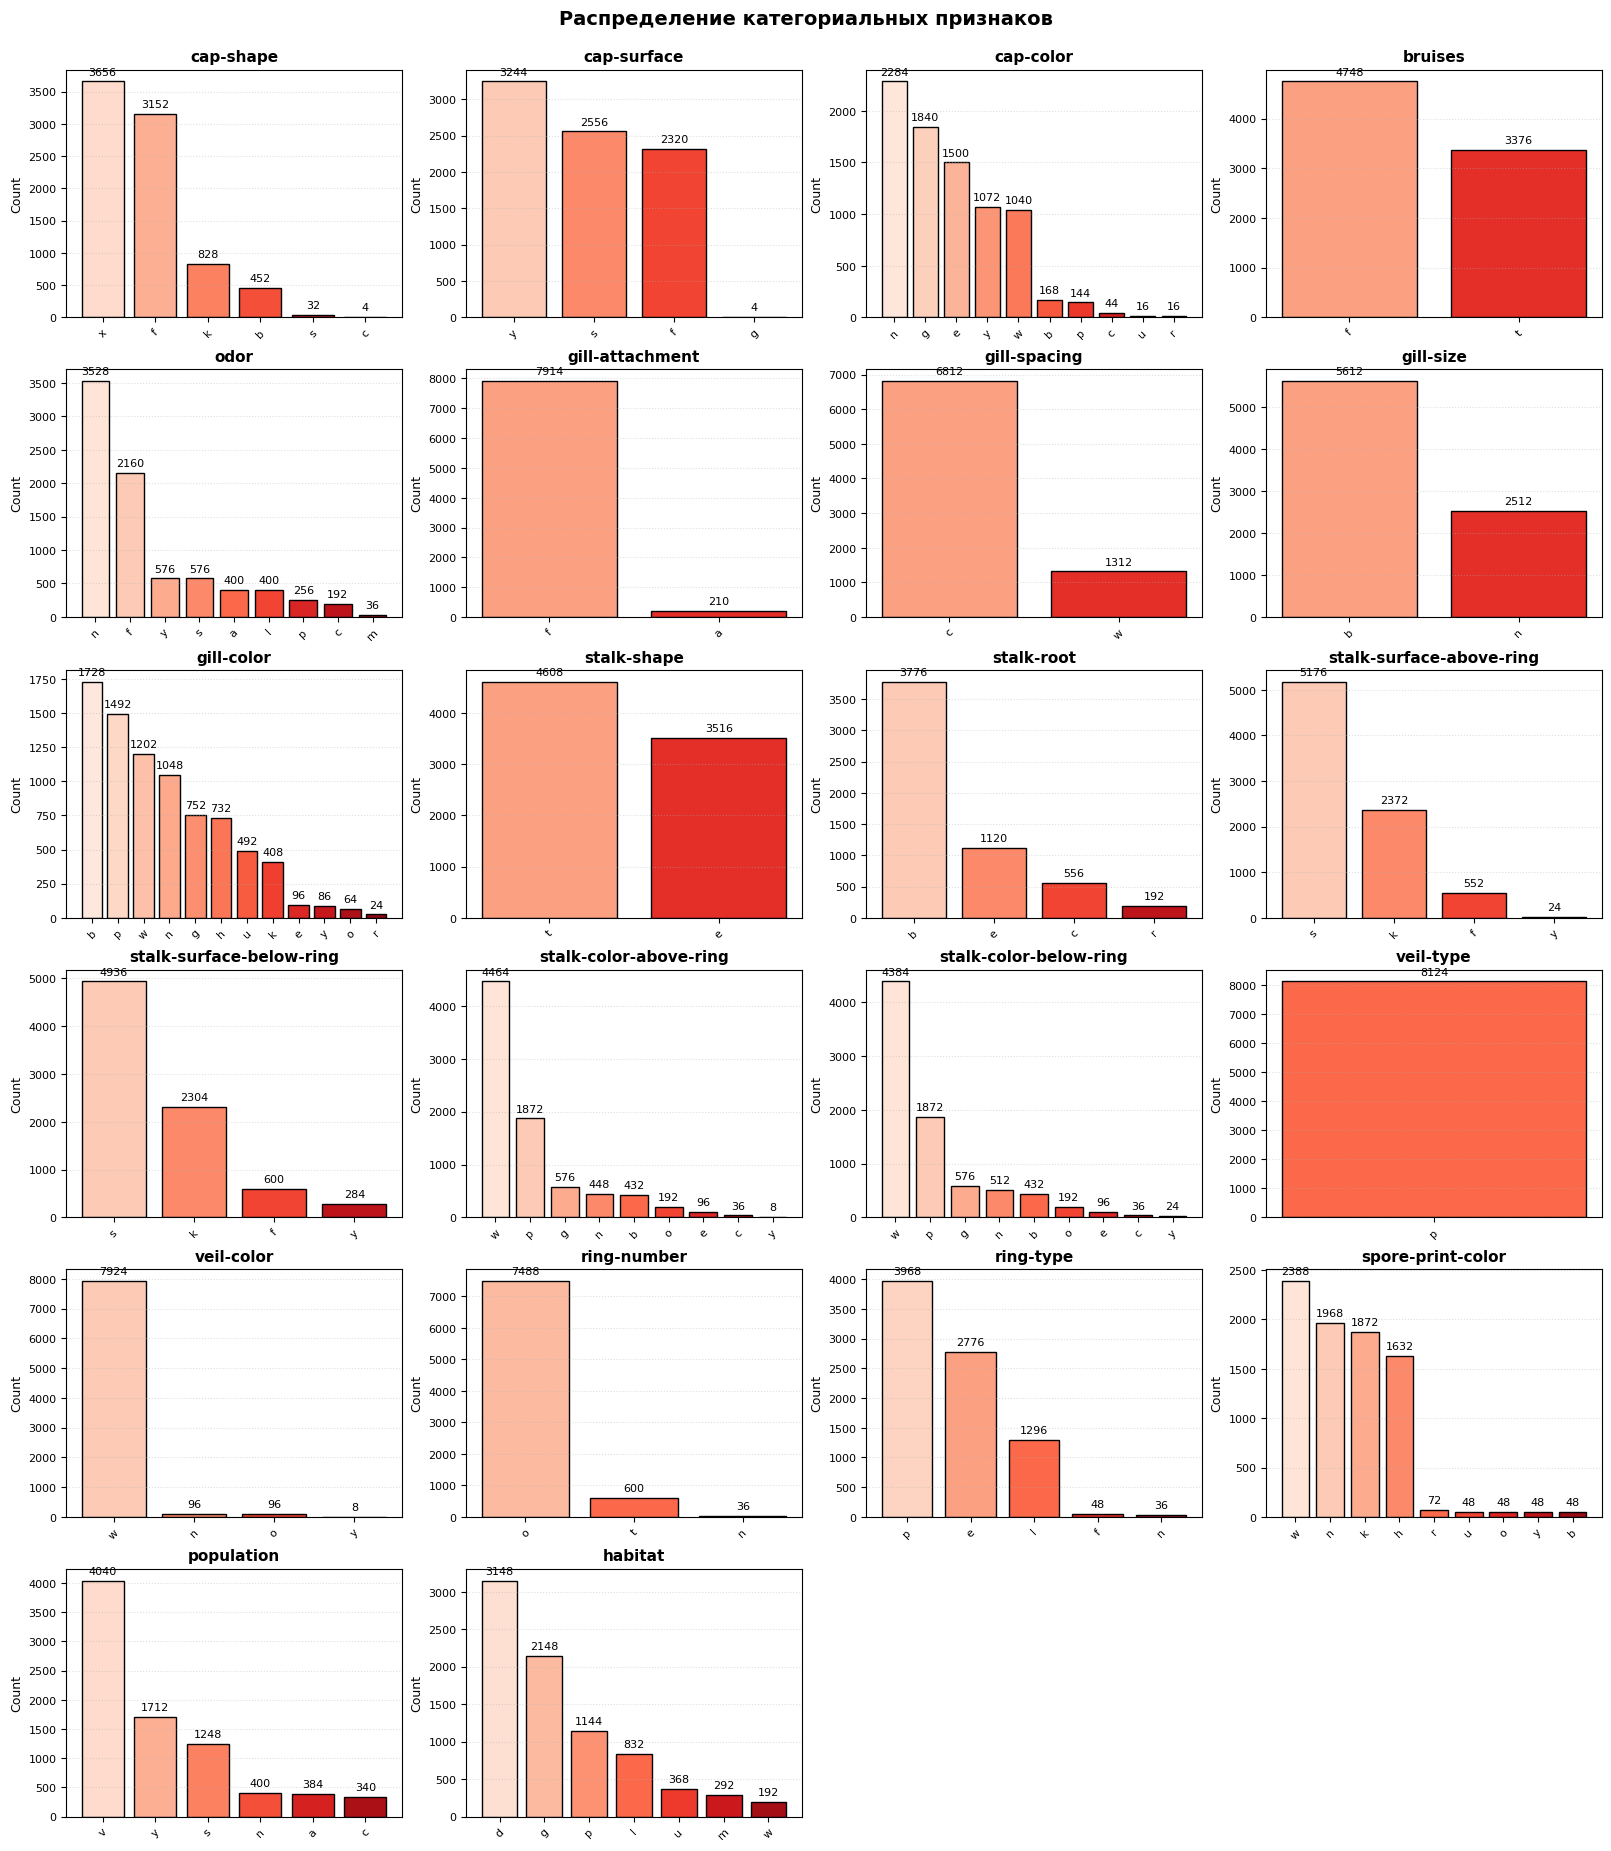

In [ ]:
cat_cols = X.columns.tolist()
n_features = len(cat_cols)

# Настроим сетку: 4 колонки, подсчитаем строки
n_cols = 4
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3), constrained_layout=True)
axes = axes.flatten()

for idx, col in enumerate(cat_cols):
    ax = axes[idx]
    counts = X[col].value_counts()
    categories = counts.index.tolist()
    values = counts.values

    # Построим bars
    bars = ax.bar(
        categories,
        values,
        color=sns.color_palette("Reds", len(categories)),
        edgecolor='black'
    )
    ax.set_title(f"{col}", fontsize=11, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Count", fontsize=9)
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis="y", linestyle=":", alpha=0.4)

    # Добавим подписи над каждым баром
    max_val = values.max()
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + max_val * 0.02,
            f"{int(height)}",
            ha='center',
            va='bottom',
            fontsize=8
        )

# Делаем так, чтобы последние две диаграммы в последней строчке не нарисовались пустыми
for j in range(n_features, n_rows * n_cols):
    fig.delaxes(axes[j])

plt.suptitle("Распределение категориальных признаков", fontsize=14, fontweight='bold', y=1.02)
plt.show()

Признак `veil-type` постоянен в этом наборе, поэтому не позволяет разделить объекты. Исключим его.

In [ ]:
X = X.drop('veil-type', axis=1)

In [ ]:
X.shape

(8124, 21)

Как и в случае с регрессией, проведём препроцессинг по результатам нашего разведывательного анализа данных.

In [ ]:
# Сначала разделяем данные, затем обучаем заполнение пропусков и кодирование.
y = y.squeeze('columns')
X_dev, X_holdout_raw, y_dev, y_holdout = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=42)
from sklearn.preprocessing import OneHotEncoder
categorical_preprocessor = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore', sparse_output=False)
)

Теперь подготовим данные для моделирования. Дерево решений в sklearn не умеет напрямую работать с категориальными признаками в виде строк. Необходимо превратить их в численные. Самый распространённый способ — one-hot encoding.

In [ ]:
X_train = categorical_preprocessor.fit_transform(X_train_raw)
X_val = categorical_preprocessor.transform(X_val_raw)
X_holdout = categorical_preprocessor.transform(X_holdout_raw)
encoded_feature_names = categorical_preprocessor[-1].get_feature_names_out(X.columns)
print('Число признаков после OHE:', X_train.shape[1])

Число признаков после OHE: 115


One-hot encoding создаёт столбец для каждого наблюдавшегося на train значения категории. Число столбцов выведено выше. Неизвестные категории validation и test кодируются нулями благодаря `handle_unknown="ignore"`.

In [ ]:
print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_holdout.shape)

Train: (4874, 115) Validation: (1625, 115) Test: (1625, 115)


### Обучение дерева классификации в sklearn

In [ ]:
'''
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(criterion='gini', # критерий расщепления
                                                 # «gini»/«entropy»
     splitter='best',               # разбиение  «best»/«random»
     max_depth=None,                # допустимая глубина
     min_samples_split=2,           # минимальная выборка для разбиения
     min_samples_leaf=1,            # минимальная мощность листа
     min_weight_fraction_leaf=0.0,  # аналогично с весом
     max_features=None,             # #признаков для нахождения разбиения
     random_state=3,
     max_leaf_nodes=None,           # допустимое число листьев
     min_impurity_decrease=0.0,     # порог изменения «зашумлённости»
     class_weight=None,             # веса классов («balanced» или словарь)
     ccp_alpha=0.0)                 # для подрезки

model.fit(X, y)
''';

Сравним деревья классификации на датасете Mushrooms для двух критериев — Джини и энтропии. Чтобы контролировать переобучение, будем использовать pre‑pruning: ограничим рост дерева гиперпараметром max_depth и посмотрим, как меняется точность на валидационной выборке.

In [ ]:
# Сравним Джини и энтропию при разных max_depth
depths = range(1, 31)

val_gini = []
val_entropy = []

for d in depths:
    model_g = DecisionTreeClassifier(criterion='gini', random_state=42, max_depth=d)
    model_e = DecisionTreeClassifier(criterion='entropy', random_state=42, max_depth=d)

    model_g.fit(X_train, y_train)
    model_e.fit(X_train, y_train)

    val_gini.append(model_g.score(X_val, y_val))
    val_entropy.append(model_e.score(X_val, y_val))

Нарисуем график зависимости точности на валидационной выборке от глубины дерева для двух критериев. По графику можно выбрать оптимальную глубину

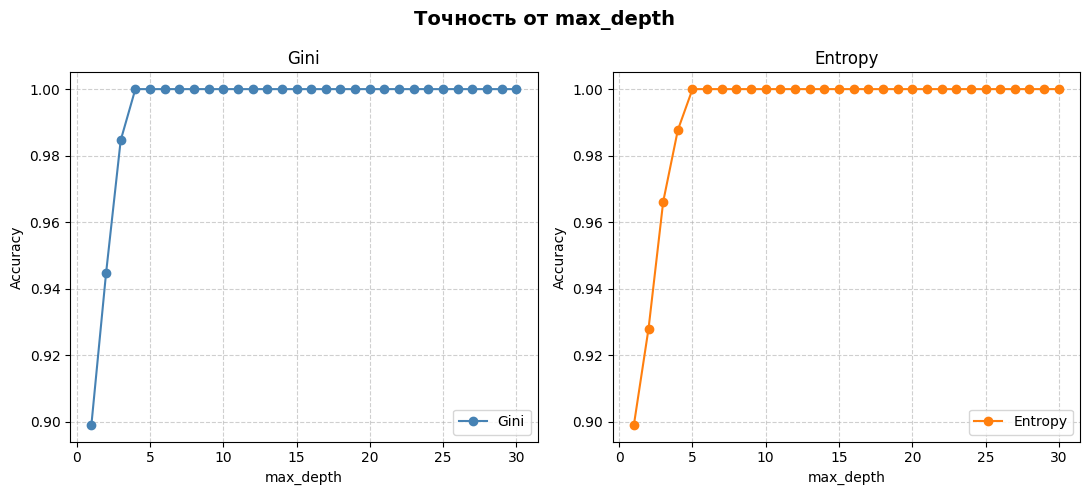

In [ ]:
plt.figure(figsize=(11,5))

plt.subplot(1,2,1)
plt.plot(depths, val_gini, marker='o', color='#4682b4', label='Gini')
plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.title('Gini')
plt.grid(True, ls='--', alpha=0.6); plt.legend()

plt.subplot(1,2,2)
plt.plot(depths, val_entropy, marker='o', color='#ff7f0e', label='Entropy')
plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.title('Entropy')
plt.grid(True, ls='--', alpha=0.6); plt.legend()

plt.suptitle("Точность от max_depth", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
best_gini_depth = depths[np.argmax(val_gini)]
best_entropy_depth = depths[np.argmax(val_entropy)]

final_gini = DecisionTreeClassifier(criterion='gini', random_state=42, max_depth=best_gini_depth)
final_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42, max_depth=best_entropy_depth)

final_gini.fit(X_train, y_train)
final_entropy.fit(X_train, y_train)

print(f"Gini: depth={best_gini_depth}, accuracy={final_gini.score(X_val, y_val):.2f}, leaves={final_gini.get_n_leaves()}")
print(f"Entropy: depth={best_entropy_depth}, accuracy={final_entropy.score(X_val, y_val):.2f}, leaves={final_entropy.get_n_leaves()}")
# Выбираем критерий по validation. При равенстве оставляем Gini.
selected_tree = final_gini if max(val_gini) >= max(val_entropy) else final_entropy
print(f"Выбранное дерево: {selected_tree.criterion}")
print(f"Итоговая test accuracy: {selected_tree.score(X_holdout, y_holdout):.4f}")

Gini: depth=4, accuracy=1.00, leaves=11
Entropy: depth=5, accuracy=1.00, leaves=11
Выбранное дерево: gini
Итоговая test accuracy: 0.9988


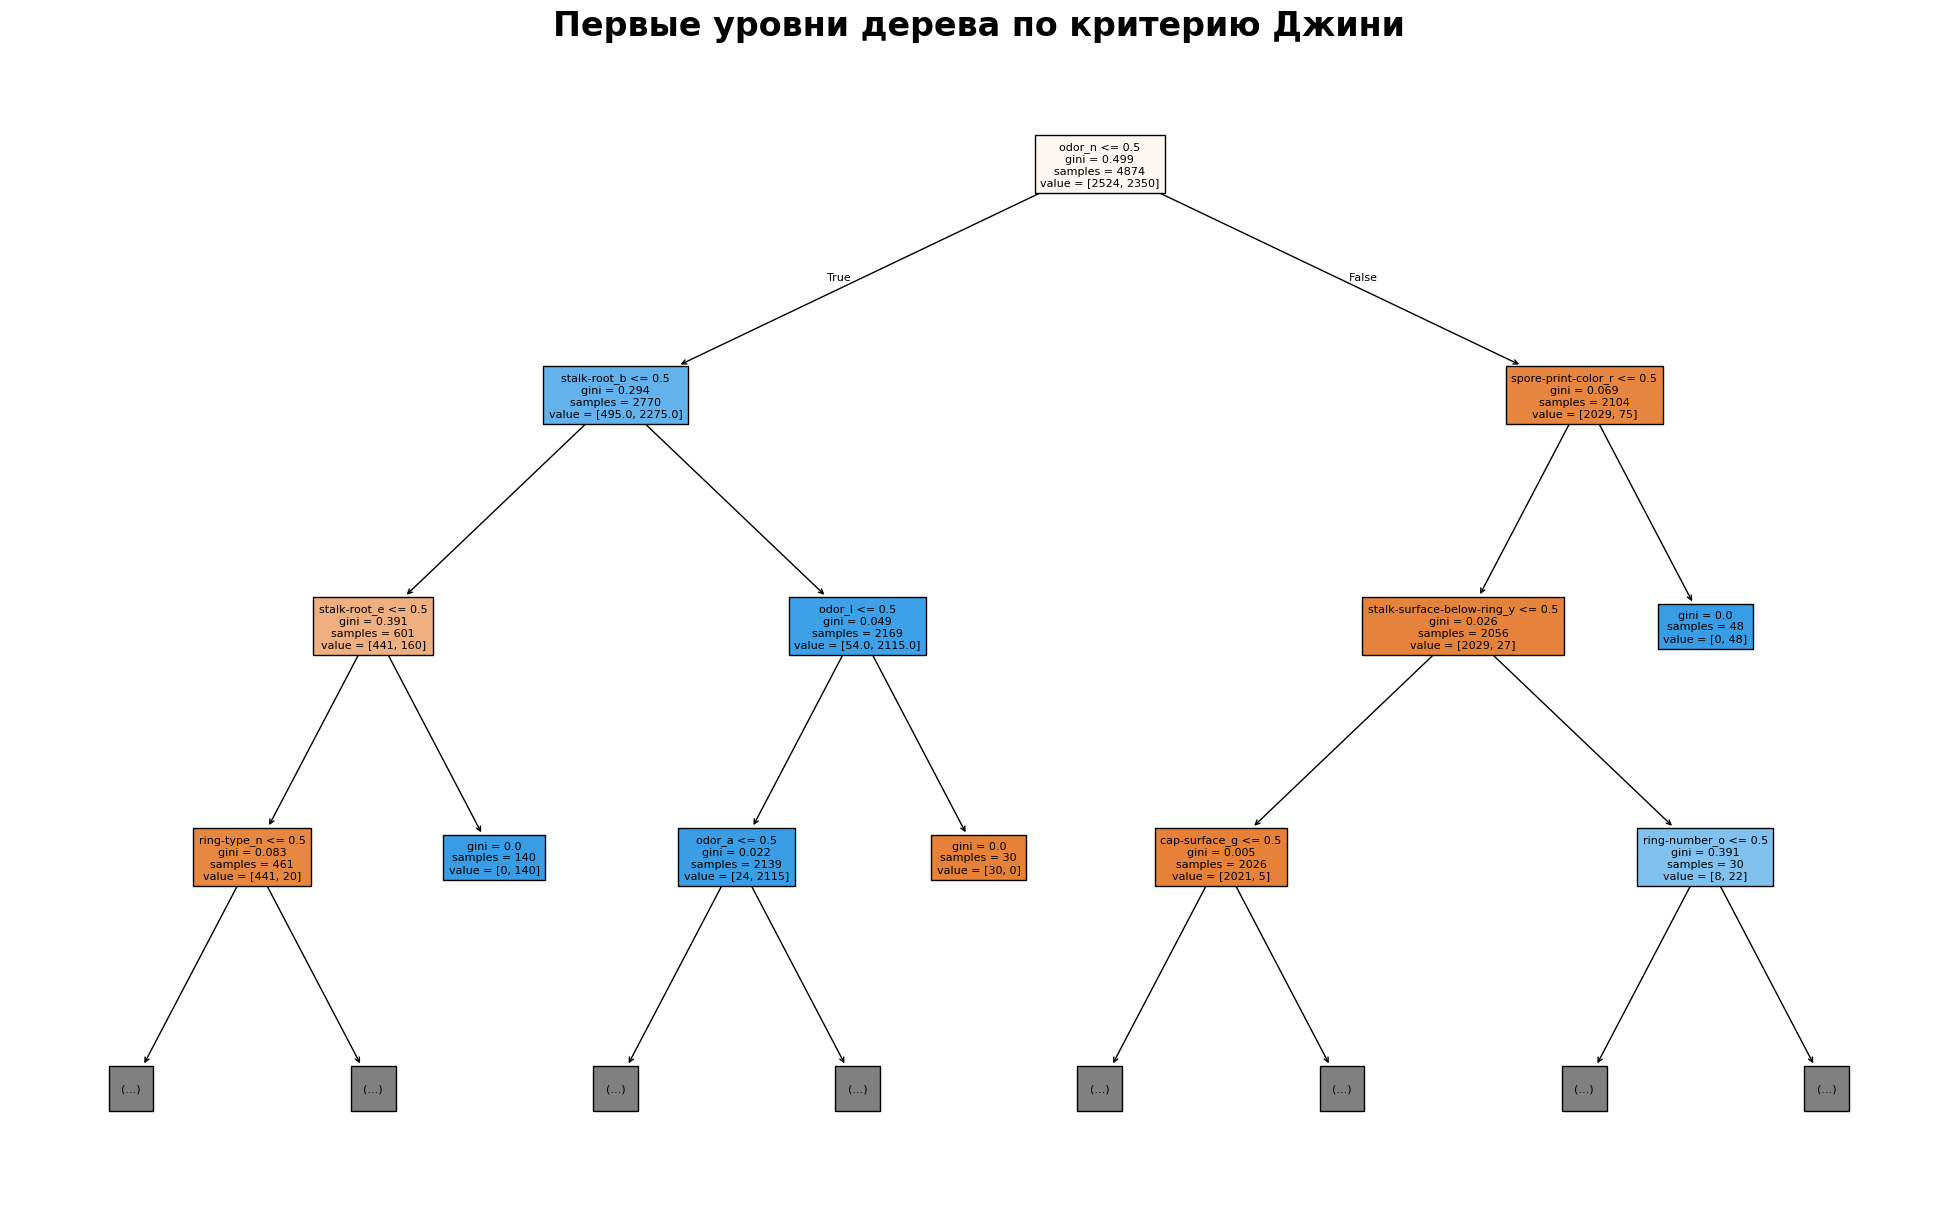

In [ ]:
plt.figure(figsize=(25,15))
tree.plot_tree(final_gini, feature_names=encoded_feature_names, filled=True, max_depth=3, fontsize=8)
plt.title("Первые уровни дерева по критерию Джини", fontsize=24, fontweight='bold', pad=10)
plt.show()

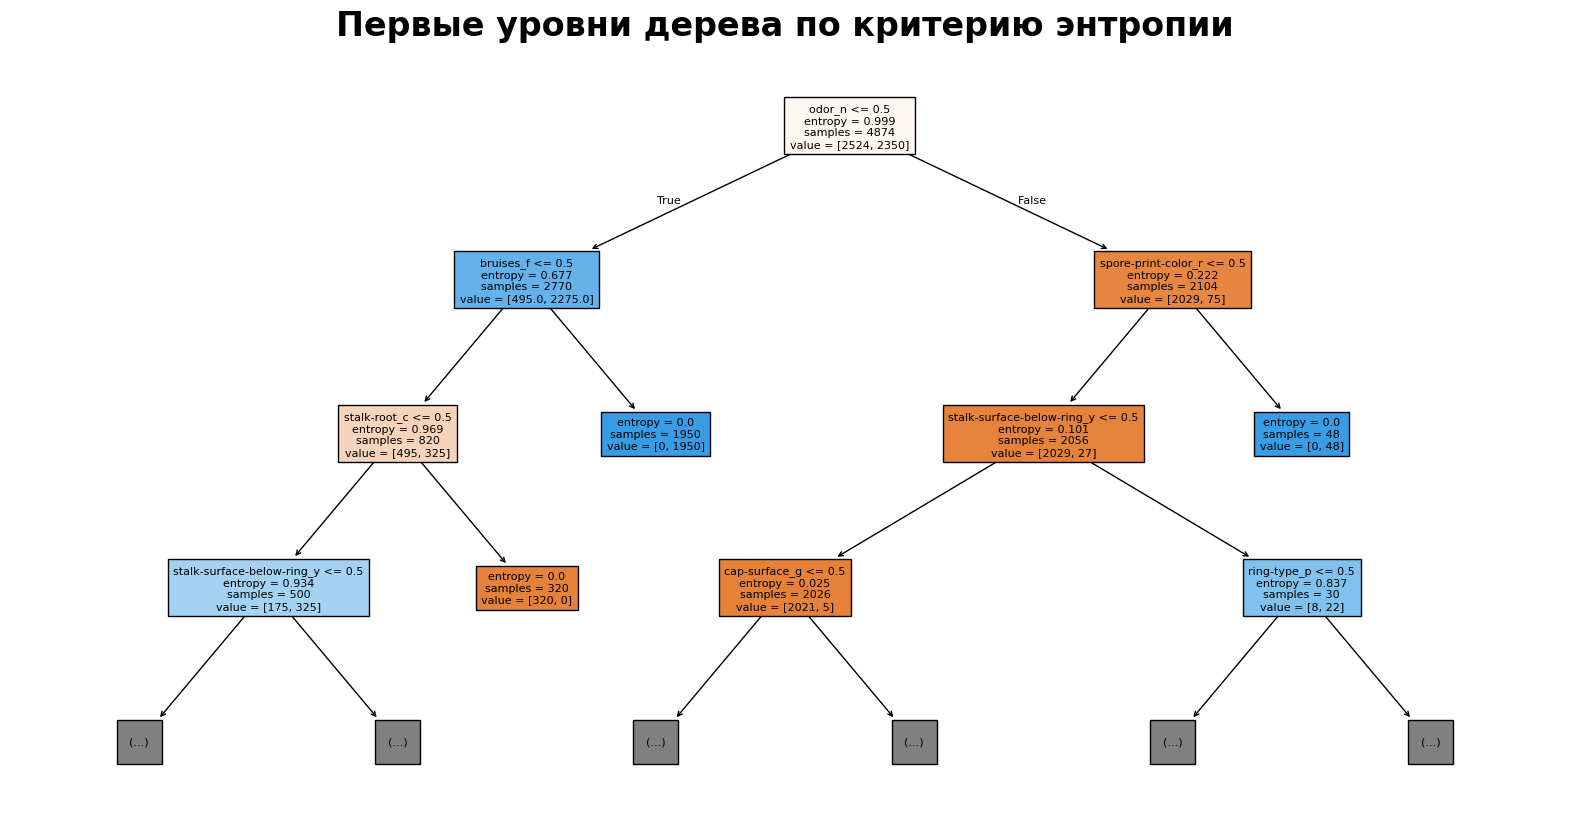

In [ ]:
plt.figure(figsize=(20,10))
tree.plot_tree(final_entropy, feature_names=encoded_feature_names, filled=True, max_depth=3, fontsize=8)
plt.title("Первые уровни дерева по критерию энтропии", fontsize=24, fontweight='bold', pad=10)
plt.show()

На Mushroom деревья могут получить высокую accuracy уже при небольшой глубине: категории признаков хорошо разделяют метки этого набора. Сравни validation accuracy двух критериев и итоговую test accuracy выбранного дерева. Даже нулевая ошибка на этих объектах не гарантирует безошибочных прогнозов на новых данных.

Джини и энтропия могут выбирать разные разбиения. Сравни их структуру, глубину и качество по полученным результатам.

**Для преподавателя.** На validation оба критерия достигают accuracy 1,000, впервые при глубине 4 для Джини и 5 для энтропии. По заданному правилу при равенстве выбрано дерево Джини. Его test accuracy около 0,9988: два неверных ответа на 1625 объектах. Разбиения двух деревьев различаются. Большая численная энтропия сама по себе не означает более сильной защиты от переобучения.

## Теперь ты умеешь

- Обучать дерево решений, используя sklearn
- Оценивать качество дерева (train/test)
- Визуализировать дерево решений
- Ограничивать дерево (для борьбы с переобучением)
- Оценивать важность признаков с помощью древесной структуры


# Обратная связь по семинару для очной магистратуры

Пройди короткий опрос по [ссылке](https://polls.tbank.ru/s/cmt6wf8lr000s0ds6c5a0gedj) или QR-коду ниже.

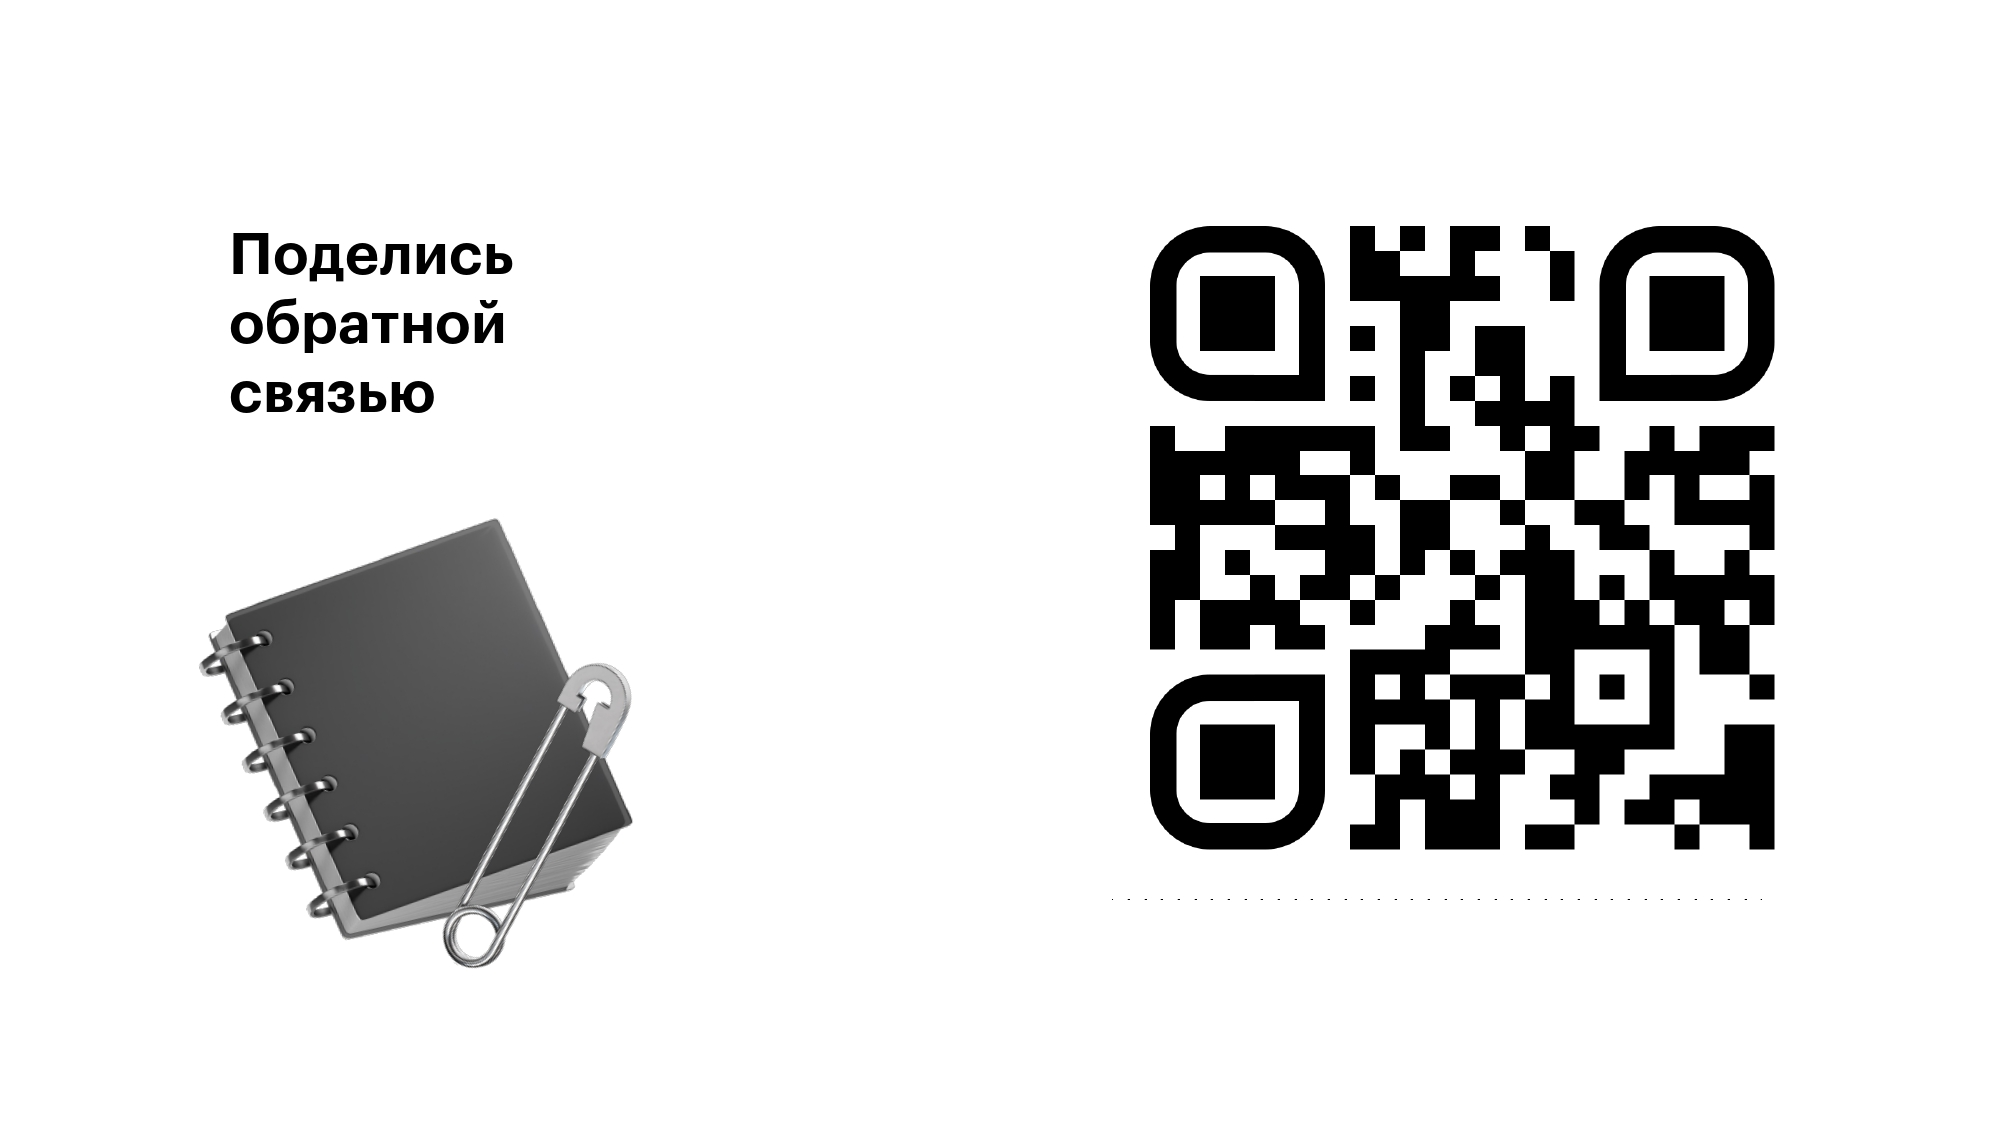

# Обратная связь по семинару для онлайн-магистратуры

Пройди короткий опрос по [ссылке](https://polls.tbank.ru/s/cms63133e00440dribvbmail8) или QR-коду ниже.

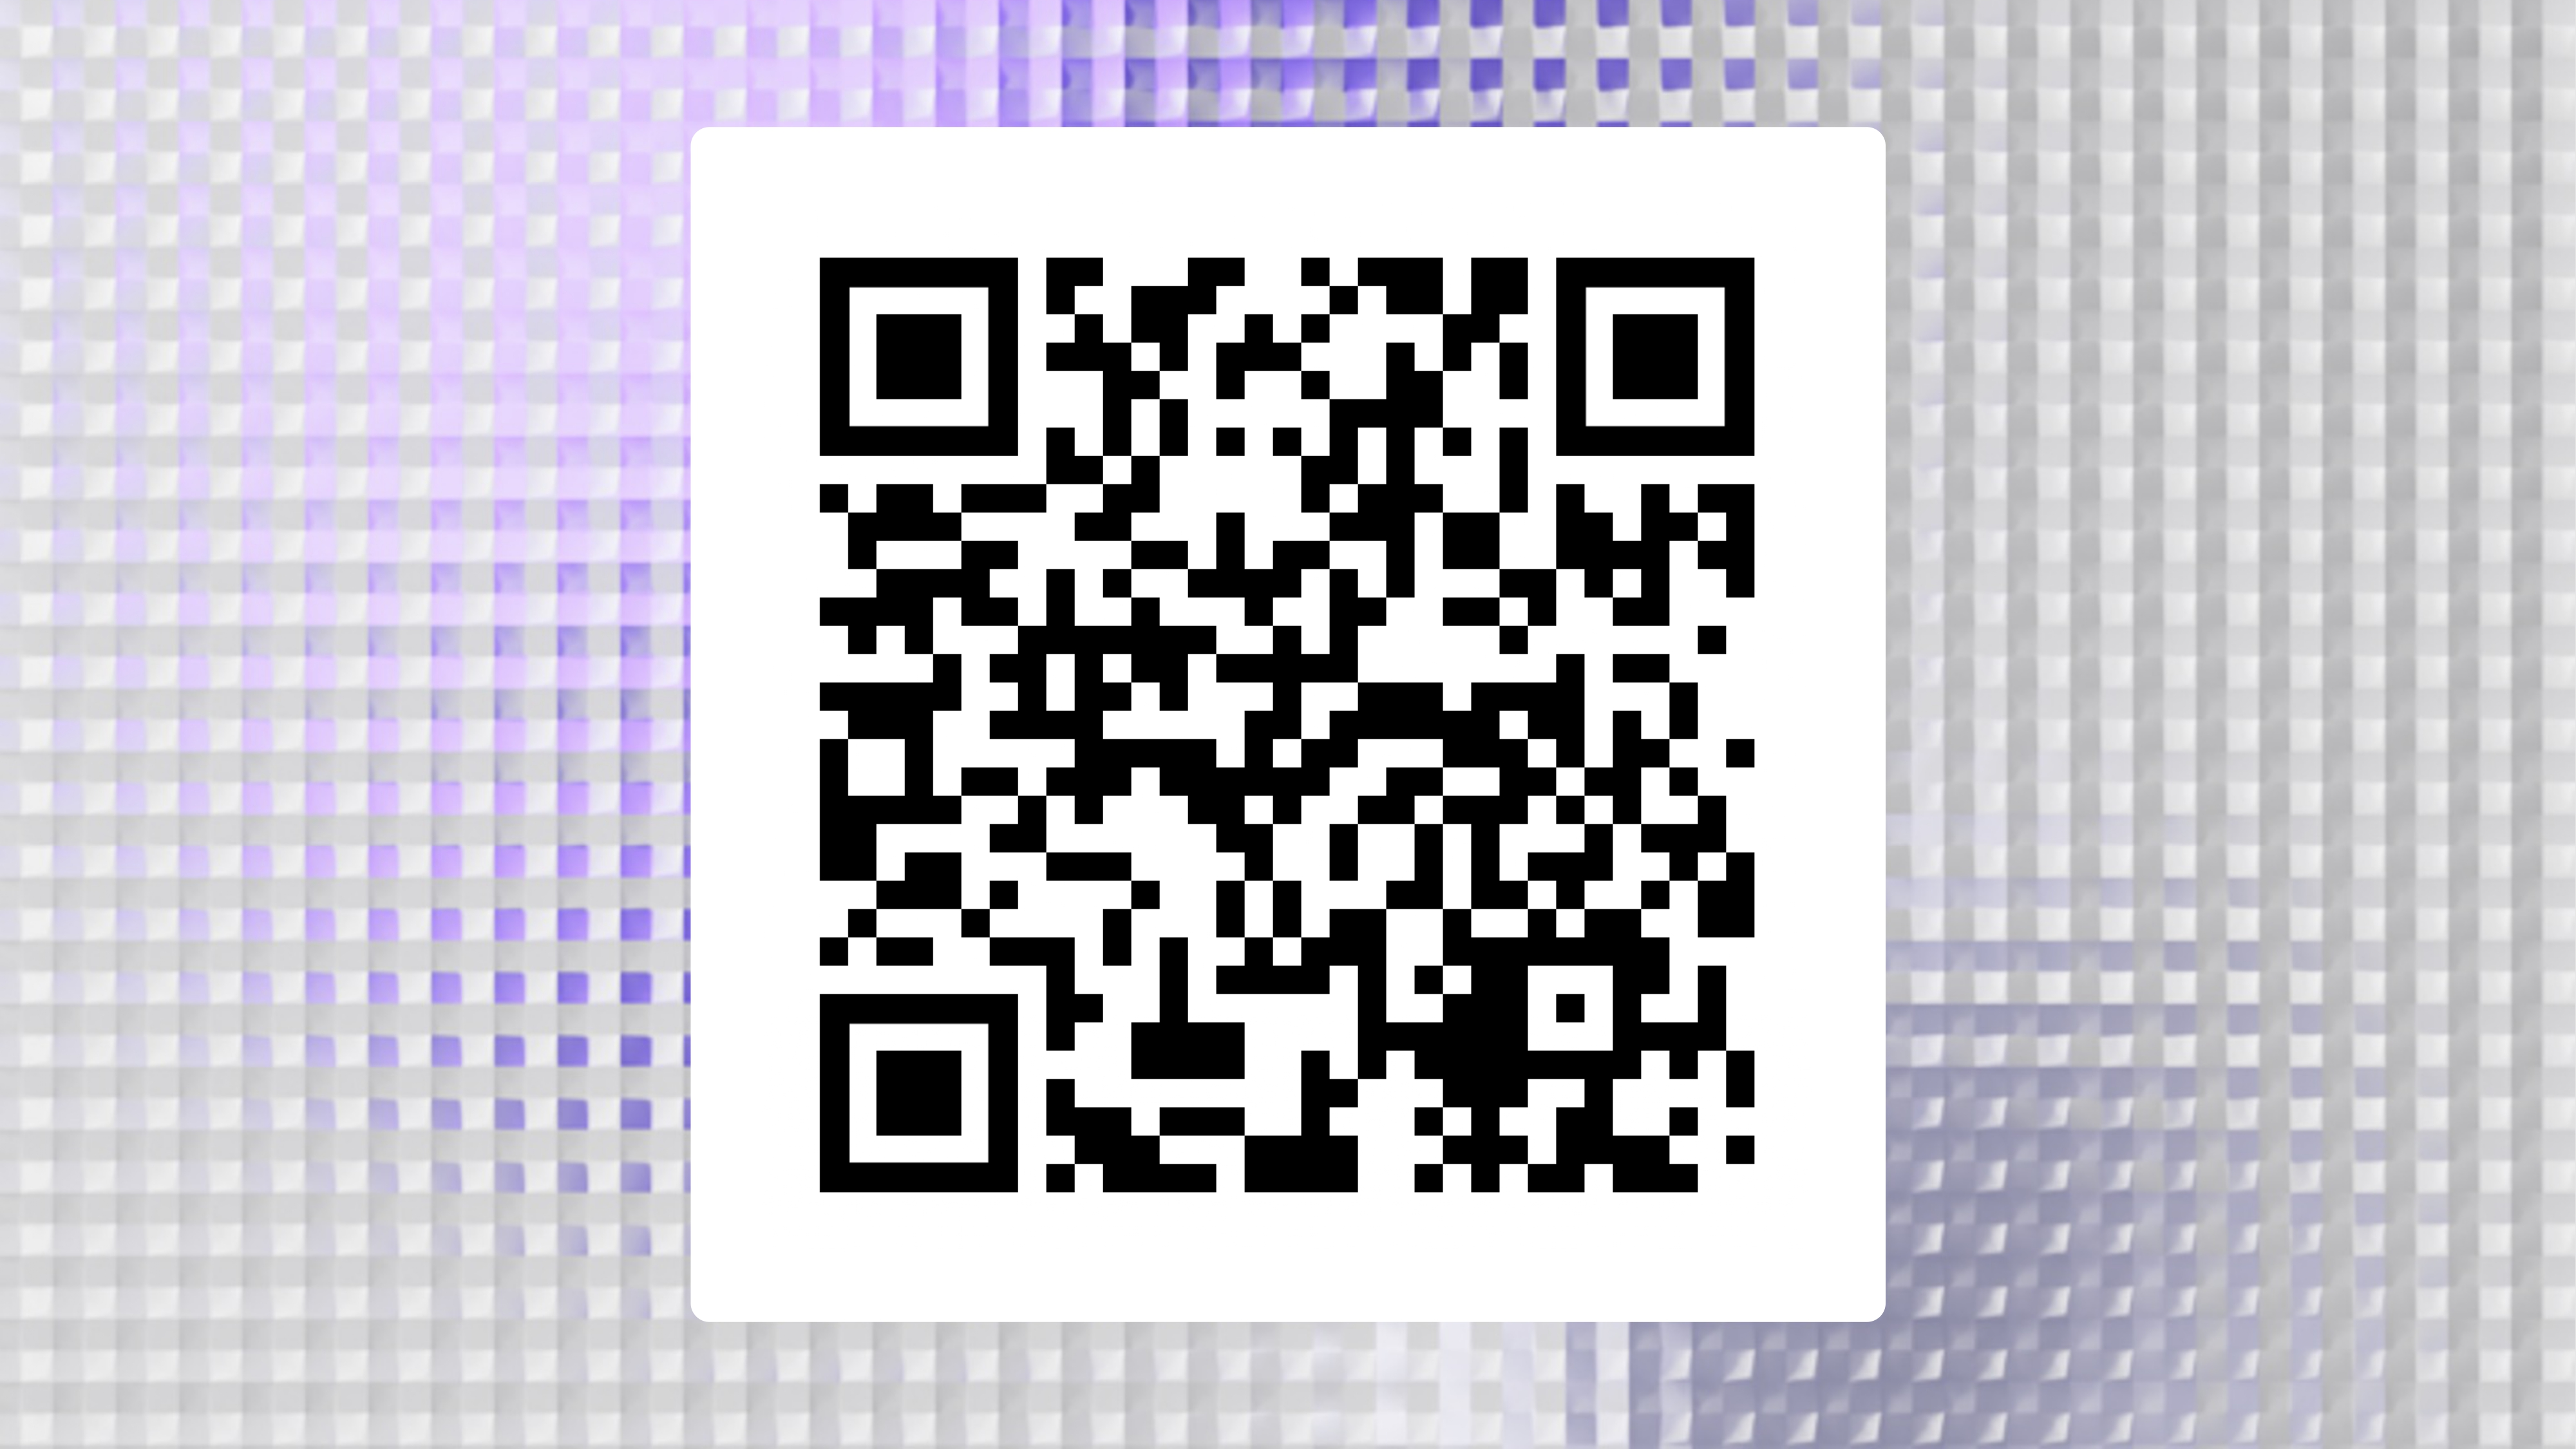